# Livrable final : tournées de livraison avec capacité et fenêtres de temps (CVRPTW)

**Projet CesiCDP (appel à manifestation d'intérêt de l'ADEME) | Groupe 6**

Étudiants : *à compléter*

---

**Plan du notebook**

1. Contexte et objectif
2. Modélisation : données, complexité, modèle PLNE
3. La méthode exacte et ses limites
4. Notre méthode : le recuit simulé
5. Implémentation en Python
6. Démonstration sur plusieurs instances
7. Validation sur les instances de référence
8. Étude expérimentale
9. Conclusion, limites et améliorations
10. Sources

Pour relancer le notebook : `pip install -r requirements.txt`, puis l'ouvrir dans le dossier `algorithme/` (il lit les instances dans `instances/` et `solomon/`, et les résultats des expériences dans `resultats/`).

## 1. Contexte et objectif

L'ADEME cherche des solutions pour rendre les transports moins polluants. Notre équipe travaille sur les **tournées de livraison** : une entreprise a un dépôt, des clients à livrer et plusieurs camions de même capacité. Chaque camion part du dépôt, livre des clients puis revient. On veut que **le temps passé sur la route soit le plus petit possible** : moins de route, c'est moins de carburant et moins de pollution.

Nous traitons deux versions du problème :

- **CVRP (niveau B)** : chaque camion a une capacité à ne pas dépasser ;
- **CVRPTW (niveau A)** : en plus, chaque client a une **fenêtre de temps**. Il est interdit de livrer après la fermeture de la fenêtre, et si le camion arrive avant l'ouverture il **attend sur place**.

**Ce que le sujet demande :**

- un modèle mathématique (PLNE) et la preuve de complexité ;
- une métaheuristique en Python capable de traiter de grandes instances ;
- une validation sur des instances de référence avec le calcul du gap par rapport aux meilleures solutions connues ;
- une étude expérimentale sur au moins 20 instances.

**Comment nous avons avancé.** Nous avons d'abord modélisé le problème (partie 2), puis regardé jusqu'où une méthode exacte peut aller (partie 3). Comme elle est trop lente dès que les instances grandissent, nous avons programmé une métaheuristique, le **recuit simulé** (parties 4 et 5). Le même programme traite les deux versions du problème : sans fenêtres il résout le CVRP, avec fenêtres le CVRPTW. Nous l'avons ensuite testé sur 80 instances de référence (parties 6 à 8).

## 2. Modélisation

### 2.1 Les données

Les lieux (le dépôt et les clients) sont les **sommets d'un graphe complet** : entre deux lieux $i$ et $j$ il existe toujours un trajet possible. Sur une vraie carte, deux lieux ne sont pas toujours reliés directement ; la durée $d_{ij}$ est alors celle du **plus court chemin** sur le réseau routier.

- le dépôt est noté 0 et les $n$ clients sont notés $1, \dots, n$ ;
- $d_{ij}$ : durée du trajet de $i$ à $j$ ;
- $q_i$ : demande du client $i$ ; $Q$ : capacité d'un camion ; $k$ : nombre de camions ;
- $[a_i, b_i]$ : **fenêtre de temps** du client $i$ (la livraison doit commencer entre $a_i$ et $b_i$) ;
- $s_i$ : durée de la livraison chez le client $i$ (temps de service) ;
- $[a_0, b_0]$ : horaires d'ouverture du dépôt (les camions partent après $a_0$ et rentrent avant $b_0$).

On suppose $q_i \le Q$ pour chaque client.

### 2.2 Une solution et ce qu'on minimise

Une **solution** est un ensemble de tournées. Chaque tournée part du dépôt, passe par des clients et revient au dépôt. Elle est valable si :

- chaque client est livré **une seule fois** ;
- on utilise **au plus $k$ camions** ;
- la somme des demandes d'une tournée **ne dépasse pas $Q$** ;
- chaque livraison commence **dans la fenêtre** du client. Un camion en avance attend l'ouverture ; un camion qui arriverait après $b_i$ rend la tournée interdite ;
- chaque camion est **rentré au dépôt avant $b_0$**.

On minimise le **temps de trajet total** (la somme des durées de tous les trajets utilisés), ce qui correspond au temps pendant lequel les moteurs tournent. Le temps d'attente n'est pas compté : on suppose le moteur coupé.

Sans fenêtres de temps (tous les $a_i = 0$ et $b_i = +\infty$), on retrouve le CVRP.

### 2.3 Complexité

On transforme le problème en question à réponse OUI ou NON en ajoutant un nombre $B$ :

> **CVRP-décision** : existe-t-il des tournées valables dont le temps de trajet total est inférieur ou égal à $B$ ?

**Le problème est dans NP.** Si on nous donne des tournées, on vérifie vite qu'elles conviennent : chaque client apparaît une seule fois, il y a au plus $k$ camions, chaque charge est inférieure ou égale à $Q$, on calcule les heures d'arrivée dans l'ordre pour contrôler les fenêtres, puis on additionne les durées et on compare avec $B$. Tout cela se fait en temps polynomial.

**Le problème est NP-difficile.** On le montre par une réduction depuis le **cycle hamiltonien**, connu comme NP-complet (Karp, 1972) : dans un graphe $G$, existe-t-il un cycle qui passe une seule fois par chaque sommet ?

On prend un graphe $G$ à $n+1$ sommets et on construit un CVRP :

- un sommet est le dépôt, les $n$ autres sont les clients ;
- le graphe est complet : la durée d'un trajet vaut **1** si $i$ et $j$ sont reliés dans $G$, et **2** sinon ;
- chaque client demande 1, la capacité est $Q = n$, il y a un seul camion ($k = 1$) ;
- on prend $B = n+1$.

La capacité ne gêne jamais et il n'y a qu'une tournée : elle passe une fois par chaque client et utilise $n+1$ trajets.

- Si $G$ a un cycle hamiltonien, le camion le suit : $n+1$ trajets de durée 1, donc un temps total de $n+1 = B$.
- Si le CVRP a une solution de temps inférieur ou égal à $n+1$, comme les $n+1$ trajets durent au moins 1 chacun, ils durent tous exactement 1 : ce sont des arêtes de $G$, et la tournée est un cycle hamiltonien de $G$.

La construction est rapide (une matrice de $n^2$ cases). Le cycle hamiltonien se ramène donc au CVRP : **le CVRP est NP-difficile**, et sa version décision est **NP-complète**.

**Avec les fenêtres de temps.** Le CVRP est un cas particulier du CVRPTW (il suffit de prendre des fenêtres très larges). Le CVRPTW est donc au moins aussi difficile : il est aussi **NP-difficile**. Il est même plus dur sur un point : avec des fenêtres, savoir s'il existe *une* tournée valable pour un seul camion est déjà un problème NP-complet (Savelsbergh, 1985).

**Conséquence.** On ne connaît pas d'algorithme rapide qui trouve toujours la meilleure solution (on suppose P ≠ NP). Une méthode exacte ne traite que de petites instances, alors que le projet demande des centaines à des milliers de clients. C'est ce qui justifie d'utiliser une **métaheuristique**.

### 2.4 Le modèle PLNE complet

Pour que l'ordinateur sache **quel camion** fait quel trajet et **à quel moment de la journée**, nous utilisons des variables à quatre indices. Le sujet demande de tenir compte du trafic selon les tranches horaires : la durée d'un trajet dépend de la tranche $t$ pendant laquelle on part.

**Données supplémentaires**

- $K$ : l'ensemble des camions, $T$ : l'ensemble des tranches horaires ;
- $d^{t}_{ij}$ : durée du trajet de $i$ à $j$ quand on part pendant la tranche $t$ ;
- la tranche $t$ commence à l'instant $e_t$ et finit à l'instant $e_{t+1}$ ;
- $M$ : un nombre très grand (plus grand que tous les temps possibles).

**Variables**

- $x_{ijkt} \in \{0,1\}$ : vaut 1 si le camion $k$ va directement de $i$ à $j$ en partant pendant la tranche $t$ ;
- $h_i \ge 0$ : l'heure à laquelle la livraison commence chez le client $i$. On pose $h_0 = a_0$ et $s_0 = 0$ : les camions partent à l'ouverture du dépôt.

**Objectif** : minimiser le temps de trajet total

$$\min \sum_{i}\sum_{j \neq i}\sum_{k \in K}\sum_{t \in T} d^{t}_{ij}\, x_{ijkt}$$

**Contraintes**

| N° | Contrainte | À quoi elle sert |
|---|---|---|
| (1) | $\sum_{j,k,t} x_{ijkt} = 1$ pour chaque client $i$ | un seul trajet part de chaque client |
| (2) | $\sum_{j,k,t} x_{jikt} = 1$ pour chaque client $i$ | un seul trajet arrive chez chaque client : il est livré une seule fois |
| (3) | $\sum_{j,t} x_{0jkt} \le 1$ pour chaque camion $k$ | chaque camion fait au plus une tournée |
| (4) | $\sum_{j,t} x_{0jkt} = \sum_{i,t} x_{i0kt}$ pour chaque camion $k$ | un camion qui part du dépôt y revient |
| (5) | $\sum_{t,\,j}\sum_{i \ne 0} q_i\, x_{ijkt} \le Q$ pour chaque camion $k$ | un camion ne dépasse jamais sa capacité |
| (6) | $\sum_{i,t} x_{ickt} = \sum_{j,t} x_{cjkt}$ pour chaque client $c$ et chaque camion $k$ | le camion qui arrive chez $c$ est celui qui en repart |
| (7) | $e_t - M(1 - x_{ijkt}) \le h_i + s_i \le e_{t+1} - 1 + M(1 - x_{ijkt})$ | si on quitte $i$ pendant la tranche $t$, l'heure de départ $h_i + s_i$ est bien dans cette tranche |
| (8) | $h_j \ge h_i + s_i + d^{t}_{ij} - M(1 - x_{ijkt})$ pour $j \neq 0$ | on ne peut pas commencer chez $j$ avant d'y être arrivé ; le « $\ge$ » autorise l'**attente** |
| (9) | $a_i \le h_i \le b_i$ pour chaque client $i$ | la livraison commence **dans la fenêtre** du client |
| (10) | $h_i + s_i + d^{t}_{i0} \le b_0 + M(1 - x_{i0kt})$ | le camion est rentré avant la fermeture du dépôt |

**Pourquoi il n'y a pas de sous-tours.** Un sous-tour est un petit cycle de clients qui ne passe pas par le dépôt. Avec la contrainte (8), l'heure augmente strictement à chaque trajet (les durées sont positives) : le long d'un tel cycle on aurait $h_i > h_i$, ce qui est impossible.

**Taille du modèle.** Il y a $n(n+1) \times |K| \times |T|$ variables binaires : par exemple 100 clients, 10 camions et 3 tranches donnent plus de 300 000 variables. On ne peut pas espérer l'utiliser directement sur de grandes instances.

### 2.5 Un petit exemple pour tester le modèle

Pour vérifier que le modèle est correct, nous le résolvons sur un exemple inventé de 6 lieux : un dépôt S et cinq clients A à E. Les durées sont en minutes. Il y a 3 tranches d'une heure et la deuxième est l'heure de pointe (les trajets durent 1,5 fois plus longtemps). Il y a 2 camions de capacité 8, chaque livraison dure 5 minutes, et chaque client a une fenêtre de temps.

In [1]:
import pulp          # testé avec PuLP 4 : pip install "pulp>=4.1" highspy

noms = ["S", "A", "B", "C", "D", "E"]
d = [[0, 12, 20, 27, 31, 25],
     [12, 0, 9, 15, 20, 29],
     [20, 9, 0, 19, 11, 21],
     [27, 15, 19, 0, 8, 14],
     [31, 20, 11, 8, 0, 10],
     [25, 29, 21, 14, 10, 0]]
q = [0, 2, 3, 2, 4, 3]       # demandes (exemple inventé) ; le dépôt n'a pas de demande
Q = 8                        # capacité d'un camion
nb_camions = 2

# fenêtres de temps [a_i, b_i] en minutes et durée de chaque livraison
fenetre = [(0, 180), (0, 40), (60, 120), (30, 90), (0, 180), (20, 60)]
service = [0, 5, 5, 5, 5, 5]

# trafic : 3 tranches d'une heure, la tranche 1 est l'heure de pointe (x 1,5)
debut = [0, 60, 120, 180]    # e_t : début de chaque tranche
coef = [1.0, 1.5, 1.0]
dt = [[[int(d[i][j] * coef[t] + 0.5) for j in range(6)] for i in range(6)] for t in range(3)]

In [2]:
lieux, clients = range(6), range(1, 6)
camions, tranches = range(nb_camions), range(3)
M = 500

prob = pulp.LpProblem("CVRPTW_complet", pulp.LpMinimize)

# x[i, j, k, t] = 1 si le camion k va de i à j en partant pendant la tranche t
x = {(i, j, k, t): prob.add_variable(f"x_{i}_{j}_{k}_{t}", cat="Binary")
     for i in lieux for j in lieux if i != j for k in camions for t in tranches}
# h[i] = heure de début de livraison chez i, dans sa fenêtre : contrainte (9)
h = {i: prob.add_variable(f"h_{i}", lowBound=fenetre[i][0], upBound=fenetre[i][1]) for i in clients}
h[0] = fenetre[0][0]         # les camions partent à l'ouverture du dépôt

# objectif : temps de trajet total
# (+ un tout petit terme sur les heures, pour que le solveur affiche les heures au plus tôt)
trajet_total = pulp.lpSum(dt[t][i][j] * x[i, j, k, t] for (i, j, k, t) in x)
prob += trajet_total + 0.001 * pulp.lpSum(h[i] for i in clients)

for i in clients:
    prob += pulp.lpSum(x[i, j, k, t] for j in lieux if j != i for k in camions for t in tranches) == 1   # (1)
    prob += pulp.lpSum(x[j, i, k, t] for j in lieux if j != i for k in camions for t in tranches) == 1   # (2)

for k in camions:
    depart = pulp.lpSum(x[0, j, k, t] for j in clients for t in tranches)
    retour = pulp.lpSum(x[i, 0, k, t] for i in clients for t in tranches)
    prob += depart <= 1                                                                                    # (3)
    prob += depart == retour                                                                               # (4)
    prob += pulp.lpSum(q[i] * x[i, j, k, t] for i in clients for j in lieux if j != i
                       for t in tranches) <= Q                                                             # (5)
    for c in clients:
        prob += (pulp.lpSum(x[i, c, k, t] for i in lieux if i != c for t in tranches)
                 == pulp.lpSum(x[c, j, k, t] for j in lieux if j != c for t in tranches))                  # (6)

for (i, j, k, t) in x:
    prob += h[i] + service[i] >= debut[t] - M * (1 - x[i, j, k, t])                                       # (7)
    prob += h[i] + service[i] <= debut[t + 1] - 1 + M * (1 - x[i, j, k, t])
    if j != 0:
        prob += h[j] >= h[i] + service[i] + dt[t][i][j] - M * (1 - x[i, j, k, t])                         # (8)
    else:
        prob += h[i] + service[i] + dt[t][i][0] <= fenetre[0][1] + M * (1 - x[i, j, k, t])                # (10)

etat = prob.solve(pulp.HiGHS(msg=False))
print("Statut :", etat.status.name)
print("Temps total de trajet :", round(pulp.value(trajet_total)), "min")

for k in camions:
    utilises = {(i, j): t for (i, j, kk, t) in x if kk == k and x[i, j, kk, t].value() > 0.5}
    if not utilises:
        print("camion", k, ": reste au dépôt")
        continue
    tournee, courant = [0], 0
    while True:
        courant = next(j for (i, j) in utilises if i == courant)
        tournee.append(courant)
        if courant == 0:
            break
    duree = sum(dt[utilises[a, b]][a][b] for a, b in zip(tournee, tournee[1:]))
    heures = ", ".join(f"{noms[c]} à {round(h[c].value())} min (fenêtre {fenetre[c][0]}-{fenetre[c][1]})"
                       for c in tournee[1:-1])
    print("camion", k, ":", " - ".join(noms[c] for c in tournee),
          "| charge", sum(q[c] for c in tournee), "| roule", duree, "min |", heures)

Statut : Optimal
Temps total de trajet : 128 min
camion 0 : S - A - C - E - S | charge 7 | roule 66 min | A à 12 min (fenêtre 0-40), C à 32 min (fenêtre 30-90), E à 51 min (fenêtre 20-60)
camion 1 : S - D - B - S | charge 7 | roule 62 min | D à 31 min (fenêtre 0-180), B à 115 min (fenêtre 60-120)


Le solveur trouve des tournées qui respectent la capacité, et chaque livraison commence bien dans la fenêtre du client. Le modèle fonctionne donc sur cet exemple.

**Un deuxième modèle plus léger pour la suite.** Dans la partie 3 et dans la métaheuristique, nous utilisons une version sans l'indice du camion ni celui de la tranche horaire (une seule durée $d_{ij}$ par trajet, car les instances de référence n'ont pas de trafic) :

- variables $x_{ij} \in \{0,1\}$ (le trajet de $i$ à $j$ est utilisé), $u_i$ (charge livrée après le client $i$) et $h_i$ (heure de début chez $i$) ;
- objectif : $\min \sum_{i,j} d_{ij}\, x_{ij}$ ;
- un seul départ et une seule arrivée par client, autant de retours au dépôt que de départs ;
- capacité : $u_i - u_j + Q\, x_{ij} \le Q - q_j$ et $q_i \le u_i \le Q$ ;
- fenêtres : $h_j \ge h_i + s_i + d_{ij} - M(1 - x_{ij})$ et $a_i \le h_i \le b_i$.

Il a $n(n+1)$ variables binaires au lieu de $n(n+1)|K||T|$ : il se résout beaucoup plus vite et il donne les mêmes tournées quand il n'y a pas de trafic.

**Remarque sur le résultat.** Un des camions attend chez un client alors que sa fenêtre est déjà ouverte : en repartant plus tard, il évite l'heure de pointe et son trajet de retour dure moins longtemps. Le modèle tient donc bien compte du trafic par tranche horaire.

## 3. La méthode exacte et ses limites

Avant de choisir une métaheuristique, nous avons regardé jusqu'où va la méthode exacte (le PLNE léger, résolu par PuLP avec le solveur HiGHS). Nous construisons de petites instances en gardant les $m$ premiers clients d'une instance de référence : `X-n101-k25` pour le CVRP et `rc201` pour le CVRPTW. Le solveur exact a 60 secondes. Nous comparons avec notre recuit simulé (3 secondes, 3 graines).

Le code est dans `exact_bench.py` ; le notebook relit ses résultats. Cette comparaison sert aussi de **test** : quand le PLNE prouve l'optimum, le recuit doit trouver le même coût ou un coût supérieur, jamais un coût inférieur.

In [3]:
import pandas as pd
exact = pd.read_csv("resultats/exact.csv")
exact

,probleme,instance,clients,variables_x,cout_plne,temps_plne_s,optimal_prouve,cout_recuit_meilleur,cout_recuit_moyen
0,CVRP,X-n101-k25,6,42,3006.0,0.1,True,3006.0,3006.0
1,CVRP,X-n101-k25,8,72,3546.0,1.2,True,3546.0,3546.0
2,CVRP,X-n101-k25,10,110,4249.0,12.1,True,4249.0,4269.0
3,CVRP,X-n101-k25,12,156,4830.0,15.9,True,4830.0,4830.0
4,CVRP,X-n101-k25,14,210,5295.0,60.0,False,5295.0,5295.0
5,CVRP,X-n101-k25,16,272,6221.0,60.0,False,6172.0,6172.0
6,CVRPTW,RC201,10,110,182.7,0.0,True,182.7,182.7
7,CVRPTW,RC201,20,420,327.4,0.1,True,327.4,327.4
8,CVRPTW,RC201,30,930,491.5,0.4,True,491.5,491.5
9,CVRPTW,RC201,40,1640,616.5,2.1,True,616.5,616.5


**Ce que l'on lit.**

- **CVRP** : l'optimum est prouvé jusqu'à 12 clients (en 16 secondes). À 14 clients le solveur n'arrive plus à le prouver en 60 secondes, et à 16 clients sa meilleure solution (6221) est moins bonne que celle du recuit en 3 secondes (6172).
- **CVRPTW** : sur cette instance le PLNE va plus loin, car les fenêtres de temps éliminent beaucoup de trajets impossibles. L'optimum est prouvé jusqu'à 60 clients (en 23 secondes). À 80 et 100 clients il n'est plus prouvé en 60 secondes, et le recuit fait mieux en 3 secondes (1104,6 contre 1144,2 à 80 clients).
- **Contrôle** : chaque fois que l'optimum est prouvé, le meilleur essai du recuit trouve exactement la même valeur, jamais moins. C'est un bon signe pour notre calcul des coûts et des fenêtres.

La méthode exacte est donc utile comme **référence sur de petites instances**, mais elle ne passe pas à l'échelle : c'est pour cela que la suite repose sur une métaheuristique.

C'est aussi cette comparaison qui nous a fait corriger notre méthode. Dans une première version à 4 mouvements, le recuit restait jusqu'à 8 % au-dessus de l'optimum du PLNE sur ces petites instances avec fenêtres. La cause : aucun mouvement ne pouvait créer une nouvelle tournée. Nous avons ajouté un cinquième mouvement (parties 4.3 et 8.2).

## 4. Notre méthode : le recuit simulé

### 4.1 L'idée

Le recuit simulé imite le refroidissement d'un métal. On part d'une solution, puis on répète un très grand nombre de fois :

1. on tire au hasard un **petit changement** de la solution (un « voisin ») ;
2. si le changement **raccourcit** le trajet total, on le garde ;
3. s'il l'**allonge** de $\Delta$, on le garde quand même avec la probabilité $e^{-\Delta / T}$.

$T$ est la **température**. Elle est haute au début (on accepte beaucoup de mauvais changements, ce qui permet de sortir des « pièges » où aucune amélioration simple n'existe) puis elle baisse jusqu'à presque zéro (on n'accepte plus que les améliorations). On garde toujours en mémoire la meilleure solution rencontrée.

### 4.2 Les choix que nous avons faits

| Élément | Notre choix |
|---|---|
| **Solution** | une liste de tournées, chaque tournée est la liste ordonnée de ses clients (le dépôt n'est pas écrit) |
| **Solutions autorisées** | uniquement des solutions valables : un changement qui dépasse la capacité ou qui met un camion en retard sur une fenêtre est refusé |
| **Solution de départ** | algorithme des économies de Clarke et Wright (partie 5.3), adapté aux fenêtres de temps |
| **Voisinage** | 5 types de changements (tableau ci-dessous), tirés au hasard. Probabilités : 40 %, 20 %, 20 %, 20 % pour les quatre premiers ; le cinquième n'est utilisé qu'avec des fenêtres de temps (0,5 % des tirages) |
| **Voisins proches** | on ne teste que des changements entre un client et l'un de ses $K$ clients les plus proches |
| **Température** | départ $T_0 = t_0 \times$ (longueur moyenne d'un trajet de la solution de départ), fin $T_1 = t_1 \times$ cette longueur, baisse **géométrique** au cours du temps |
| **Arrêt** | une durée fixée en secondes |
| **Coût d'un changement** | $\Delta$ = nouvelle longueur − ancienne longueur, calculé seulement sur les une ou deux tournées qui changent |

### 4.3 Les 5 changements (mouvements)

On tire un client $u$ et un de ses voisins proches $v$ :

| Mouvement | Ce qu'on fait | Tournées touchées |
|---|---|---|
| **déplacer** | on retire $u$ et on le remet juste avant ou juste après $v$ | une ou deux |
| **échanger** | $u$ et $v$ échangent leurs places | une ou deux |
| **2-opt** | on retourne le morceau de tournée entre $u$ et $v$ (enlève les croisements) | une seule |
| **2-opt\*** | on coupe les deux tournées après $u$ et après $v$ et on recolle les morceaux autrement | deux |
| **nouvelle tournée** | $u$ quitte sa tournée et part seul avec un camion de plus (seulement avec des fenêtres de temps, voir 8.2) | une + une nouvelle |

### 4.4 Comment les fenêtres de temps sont prises en compte

Pour savoir si une tournée respecte les fenêtres, on la parcourt dans l'ordre en tenant une horloge : on ajoute la durée du trajet ; si on arrive après $b_i$ la tournée est refusée ; si on arrive avant $a_i$ on avance l'horloge à $a_i$ (attente) ; puis on ajoute la durée de la livraison $s_i$. À la fin, il faut être rentré au dépôt avant $b_0$. Ce contrôle coûte un parcours de la tournée : on le fait donc **en dernier**, seulement pour les changements que le recuit a déjà décidé d'accepter.

La figure ci-dessous montre l'effet des quatre premiers mouvements sur un petit exemple.

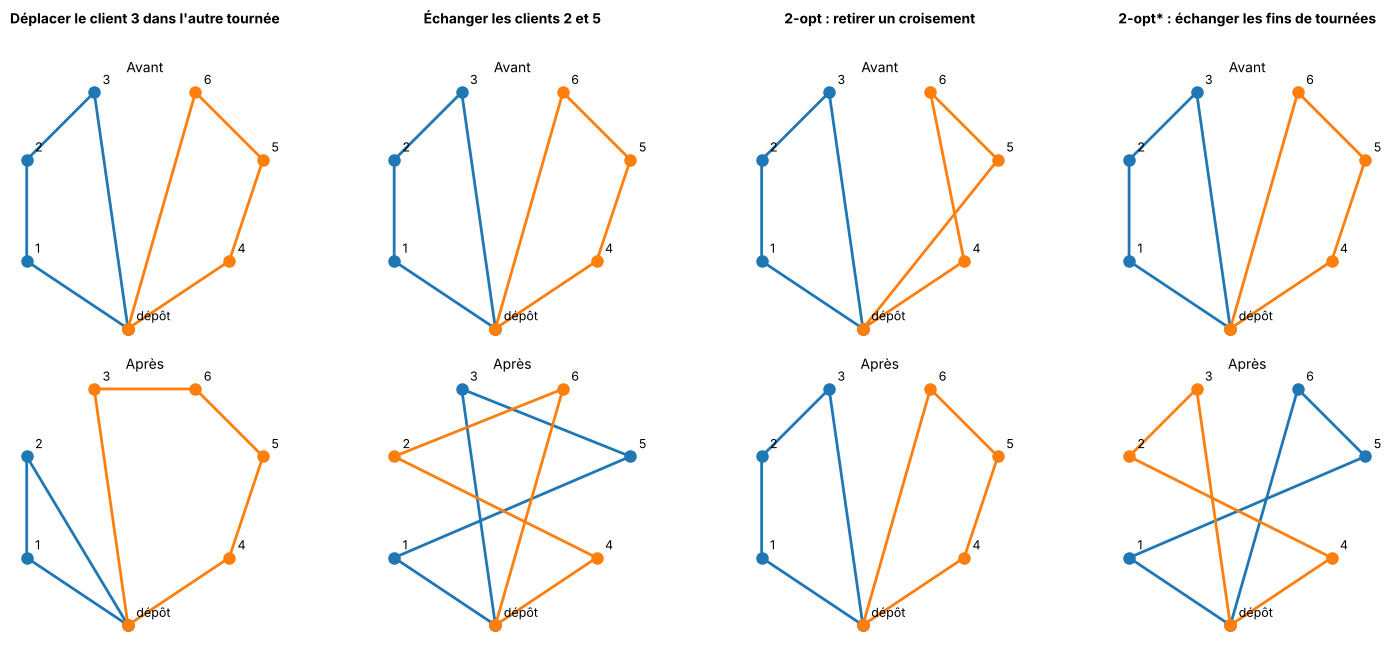

In [4]:
import matplotlib.pyplot as plt

coord_ex = {0: (0, 0), 1: (-3, 2), 2: (-3, 5), 3: (-1, 7), 4: (3, 2), 5: (4, 5), 6: (2, 7)}


def tracer(ax, tournees, titre, couleurs=("tab:blue", "tab:orange")):
    # dessine des tournées sur un petit exemple
    for tour, coul in zip(tournees, couleurs):
        chemin = [0] + tour + [0]
        ax.plot([coord_ex[c][0] for c in chemin], [coord_ex[c][1] for c in chemin],
                "-o", color=coul, lw=2, ms=8, zorder=2)
    for c, (px, py) in coord_ex.items():
        ax.annotate(str(c) if c else "dépôt", (px, py), textcoords="offset points",
                    xytext=(6, 6), fontsize=9)
    ax.set_title(titre, fontsize=10)
    ax.set_aspect("equal")
    ax.axis("off")


exemples = [
    ("Déplacer le client 3 dans l'autre tournée", [[1, 2, 3], [4, 5, 6]], [[1, 2], [4, 5, 6, 3]]),
    ("Échanger les clients 2 et 5",                [[1, 2, 3], [4, 5, 6]], [[1, 5, 3], [4, 2, 6]]),
    ("2-opt : retirer un croisement",              [[1, 2, 3], [4, 6, 5]], [[1, 2, 3], [4, 5, 6]]),
    ("2-opt* : échanger les fins de tournées",     [[1, 2, 3], [4, 5, 6]], [[1, 5, 6], [4, 2, 3]]),
]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for col, (titre, avant, apres) in enumerate(exemples):
    tracer(axes[0, col], avant, "Avant")
    tracer(axes[1, col], apres, "Après")
    axes[0, col].text(0.5, 1.22, titre, transform=axes[0, col].transAxes, ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

### 4.5 Pourquoi cette méthode

- Un changement ne touche qu'une ou deux tournées : on calcule vite ce qu'il coûte, donc on peut faire **des millions d'essais** en quelques secondes.
- La solution de départ est déjà correcte, le recuit n'a plus qu'à l'améliorer.
- La durée de calcul se règle directement : plus on laisse de temps, meilleure est la solution (partie 8.3).
- La même méthode traite les deux problèmes : les fenêtres de temps sont juste un contrôle de plus.

**Ce que la méthode ne garantit pas** : une solution optimale. Elle donne une bonne solution, mais on ne peut pas prouver que c'est la meilleure (c'est le prix à payer pour un problème NP-difficile).

## 5. Implémentation en Python

Le code est en Python pur, sans bibliothèque externe, pour rester lisible. Il est découpé en six parties. Le même code est dans le fichier `recuit_simple.py` (c'est lui que les expériences de la partie 8 utilisent).

In [5]:
# Recuit simulé pour le CVRP (camions avec capacité) et le CVRPTW (capacité + fenêtres de temps)
# dépôt = lieu 0, clients = 1..n, chaque camion porte au plus Q
# avec fenêtres : le client i doit être livré entre a_i et b_i ; si le camion arrive
# avant a_i il attend, s'il arrive après b_i la tournée est interdite
#
# plan du fichier :
#   1. lecture d'une instance (.vrp sans fenêtres, .txt de Solomon avec fenêtres)
#   2. distances et voisins proches
#   3. solution de départ (Clarke et Wright)
#   4. fonctions utiles (longueur, charge, horaires, vérification)
#   5. les 5 mouvements
#   6. le recuit + resoudre() qui enchaîne tout
#
# exemples : python recuit_simple.py instances/X-n101-k25.vrp
#            python recuit_simple.py solomon/r101.txt

import math
import random
import time

### 5.1 Lecture d'une instance

Deux formats : les fichiers `.vrp` (instances X, sans fenêtres) et les fichiers `.txt` de Solomon (avec fenêtres de temps et durées de service). Dans les deux cas le dépôt devient le lieu 0.

In [6]:
# lit un fichier .vrp ; le dépôt devient le lieu 0 et les clients 1..n
def lire_instance(chemin):
    nom = ""
    capacite = 0
    type_distance = "EUC_2D"
    coords = []
    demandes = []
    section = None

    with open(chemin, encoding="utf-8") as fichier:
        for ligne in fichier:
            ligne = ligne.strip()
            if ligne == "" or ligne == "EOF":
                continue

            # en-tête du fichier : lignes "CLE : valeur"
            if ":" in ligne:
                cle, valeur = ligne.split(":", 1)
                cle = cle.strip()
                valeur = valeur.strip()
                if cle == "NAME":
                    nom = valeur
                elif cle == "CAPACITY":
                    capacite = int(valeur)
                elif cle == "EDGE_WEIGHT_TYPE":
                    type_distance = valeur
                continue

            # on change de section (coordonnées, demandes, dépôt)
            if ligne.endswith("_SECTION"):
                section = ligne
                continue

            # sinon c'est une ligne de données de la section en cours
            morceaux = ligne.split()
            if section == "NODE_COORD_SECTION":
                coords.append((float(morceaux[1]), float(morceaux[2])))
            elif section == "DEMAND_SECTION":
                demandes.append(int(morceaux[1]))
            elif section == "DEPOT_SECTION":
                # on suppose que le dépôt est le lieu 1, sinon la numérotation est fausse
                if morceaux[0] not in ("1", "-1"):
                    raise ValueError("le dépôt doit être le lieu numéro 1")

    # coords[i] = (x, y) du lieu i, demandes[0] = 0 pour le dépôt
    return {
        "nom": nom,
        "coords": coords,
        "demandes": demandes,
        "Q": capacite,
        "arrondi": type_distance == "EUC_2D",
    }


# lit un fichier de Solomon (.txt) : mêmes informations + fenêtres de temps
# colonnes : numéro, x, y, demande, début de fenêtre, fin de fenêtre, durée de service
def lire_instance_solomon(chemin):
    with open(chemin, encoding="utf-8") as fichier:
        lignes = [ligne.split() for ligne in fichier if ligne.strip() != ""]
    nom = lignes[0][0]
    coords = []
    demandes = []
    fenetres = []
    services = []
    capacite = 0
    for k in range(len(lignes)):
        morceaux = lignes[k]
        # la ligne qui suit "NUMBER CAPACITY" donne le nombre de camions et la capacité
        if morceaux[0] == "NUMBER":
            capacite = int(lignes[k + 1][1])
        # une ligne de 7 nombres = un lieu (la première est le dépôt)
        if len(morceaux) == 7 and morceaux[0].isdigit():
            coords.append((float(morceaux[1]), float(morceaux[2])))
            demandes.append(int(float(morceaux[3])))
            fenetres.append((float(morceaux[4]), float(morceaux[5])))
            services.append(float(morceaux[6]))
    return {
        "nom": nom,
        "coords": coords,
        "demandes": demandes,
        "Q": capacite,
        # convention des instances de Solomon sur CVRPLIB : distances coupées à 1 décimale
        "arrondi": "dixieme",
        "fenetres": fenetres,   # fenetres[i] = (a_i, b_i) ; fenetres[0] = horaires du dépôt
        "services": services,   # durée de la livraison chez chaque client
    }

### 5.2 Les distances et les voisins proches

On calcule une fois pour toutes la matrice $D$ des distances. Les deux familles d'instances n'ont pas la même convention : distances arrondies à l'entier pour les instances X, coupées à une décimale pour celles de Solomon. On respecte la convention de chaque famille, sinon les coûts ne seraient pas comparables aux meilleures solutions connues.

Pour chaque client on garde aussi la liste de ses $K$ plus proches voisins.

In [7]:
# matrice des distances : D[i][j] = distance entre le lieu i et le lieu j
# arrondi = True : entier le plus proche (instances .vrp)
# arrondi = "dixieme" : coupé à 1 décimale (instances de Solomon), False : rien
def calcul_distances(coords, arrondi=True):
    nb_lieux = len(coords)
    D = []
    for i in range(nb_lieux):
        ligne = []
        for j in range(nb_lieux):
            dx = coords[i][0] - coords[j][0]
            dy = coords[i][1] - coords[j][1]
            # Pythagore
            d = math.sqrt(dx * dx + dy * dy)
            if arrondi == "dixieme":
                d = math.floor(d * 10) / 10
            elif arrondi:
                d = math.floor(d + 0.5)  # convention EUC_2D
            ligne.append(d)
        D.append(ligne)
    return D


# pour chaque client, ses K clients les plus proches (voisins[0] = dépôt, vide)
# le recuit ne teste que des mouvements entre voisins proches : ça évite de perdre
# du temps à échanger deux clients qui sont aux deux bouts de la carte
def voisins_proches(D, K):
    n = len(D) - 1
    # on ne peut pas avoir plus de n-1 voisins
    K = min(K, n - 1)
    voisins = [[]]
    for i in range(1, n + 1):
        autres = [j for j in range(1, n + 1) if j != i]
        # tri du plus proche au plus loin, on garde les K premiers
        autres.sort(key=lambda j: D[i][j])
        voisins.append(autres[:K])
    return voisins

### 5.3 La solution de départ : Clarke et Wright

Au départ, chaque client a sa propre tournée dépôt → client → dépôt. Fusionner deux tournées (le client $i$ est au bout de l'une, le client $j$ au bout de l'autre) évite un aller-retour au dépôt : on **économise** $s(i,j) = d(0,i) + d(0,j) - d(i,j)$.

On traite les couples de clients dans l'ordre des plus grosses économies, et on fusionne tant que la capacité $Q$ est respectée. Avec des fenêtres de temps, on vérifie en plus que la tournée fusionnée est à l'heure (en essayant les deux sens de parcours).

In [8]:
# on fusionne les tournées dans l'ordre des plus grosses économies
# s(i, j) = D[0][i] + D[0][j] - D[i][j] tant que la capacité est respectée
# (et les fenêtres de temps, s'il y en a)
def clarke_wright(D, demandes, Q, fenetres=None, services=None):
    n = len(D) - 1

    # au début chaque client a sa propre tournée
    tournees = {i: [i] for i in range(1, n + 1)}
    charge = {i: demandes[i] for i in range(1, n + 1)}
    ou = list(range(n + 1))  # ou[c] = numéro de la tournée du client c

    # économies sur tous les couples i < j ((i, j) et (j, i) c'est pareil)
    economies = []
    for i in range(1, n + 1):
        for j in range(i + 1, n + 1):
            s = D[0][i] + D[0][j] - D[i][j]
            if s > 0:
                economies.append((s, i, j))
    # on traite les plus grosses économies en premier
    economies.sort(reverse=True)

    for s, i, j in economies:
        ti = ou[i]
        tj = ou[j]
        # déjà dans la même tournée, ou camion trop chargé -> on passe
        if ti == tj:
            continue
        if charge[ti] + charge[tj] > Q:
            continue

        A = tournees[ti]
        B = tournees[tj]
        # i et j doivent être chacun à un bout de leur tournée
        if i not in (A[0], A[-1]) or j not in (B[0], B[-1]):
            continue
        # on met i à la fin de A et j au début de B (en retournant si besoin)
        if A[-1] != i:
            A = A[::-1]
        if B[0] != j:
            B = B[::-1]
        fusion = A + B

        if fenetres is not None:
            # avec des fenêtres le sens de parcours compte : on essaie les deux sens
            if not horaires_ok(fusion, D, fenetres, services):
                fusion = fusion[::-1]
                if not horaires_ok(fusion, D, fenetres, services):
                    continue

        # fusion acceptée : la tournée tj disparaît
        tournees[ti] = fusion
        charge[ti] += charge[tj]
        for c in tournees[tj]:
            ou[c] = ti
        del tournees[tj]
        del charge[tj]

    return list(tournees.values())


# s'il y a plus de tournées que de camions, on vide la moins chargée
# et on remet ses clients là où ça rallonge le moins
def reduire_nb_tournees(tournees, D, demandes, Q, k_max, fenetres=None, services=None):
    tournees = [t[:] for t in tournees]
    while len(tournees) > k_max:
        # on enlève la tournée la moins chargée
        tournees.sort(key=lambda t: charge_de(t, demandes))
        petite = tournees.pop(0)

        for c in petite:
            meilleur = None  # (rallonge, tournée, position)
            # on cherche la tournée et la position où c rallonge le moins le trajet
            for t in tournees:
                if charge_de(t, demandes) + demandes[c] > Q:
                    continue
                # on teste toutes les positions possibles (0 = dépôt aux deux bouts)
                for p in range(len(t) + 1):
                    if p > 0:
                        avant = t[p - 1]
                    else:
                        avant = 0
                    if p < len(t):
                        apres = t[p]
                    else:
                        apres = 0
                    rallonge = D[avant][c] + D[c][apres] - D[avant][apres]
                    if meilleur is not None and rallonge >= meilleur[0]:
                        continue
                    # avec des fenêtres, il faut que la tournée reste à l'heure
                    if fenetres is not None and not horaires_ok(t[:p] + [c] + t[p:], D, fenetres, services):
                        continue
                    meilleur = (rallonge, t, p)
            if meilleur is None:
                raise ValueError(f"impossible de tout livrer avec {k_max} camions")
            # on insère c au meilleur endroit trouvé
            meilleur[1].insert(meilleur[2], c)
    return tournees

### 5.4 Les fonctions utiles

Longueur et charge d'une tournée, contrôle des horaires (`horaires_ok`), et `verifier` qui contrôle une solution complète : chaque client une seule fois, capacité, nombre de camions, fenêtres de temps. Toutes les solutions de ce notebook passent par `verifier`.

In [9]:
# longueur d'une tournée : dépôt -> clients -> dépôt
def longueur(tournee, D):
    if len(tournee) == 0:
        return 0
    # dépôt -> premier client, puis client -> client, puis dernier client -> dépôt
    total = D[0][tournee[0]]
    for k in range(len(tournee) - 1):
        total += D[tournee[k]][tournee[k + 1]]
    total += D[tournee[-1]][0]
    return total


# quantité totale livrée par une tournée
def charge_de(tournee, demandes):
    total = 0
    for c in tournee:
        total += demandes[c]
    return total


# vrai si la tournée respecte toutes les fenêtres de temps
# le camion part du dépôt à l'ouverture ; le temps de trajet = la distance
def horaires_ok(tournee, D, fenetres, services):
    heure = fenetres[0][0]
    avant = 0
    for c in tournee:
        heure += D[avant][c]            # on roule jusqu'au client c
        if heure > fenetres[c][1]:
            return False                # arrivé après la fermeture : interdit
        if heure < fenetres[c][0]:
            heure = fenetres[c][0]      # arrivé trop tôt : on attend l'ouverture
        heure += services[c]            # durée de la livraison
        avant = c
    # il faut aussi être rentré au dépôt avant sa fermeture
    return heure + D[avant][0] <= fenetres[0][1]


# détail des horaires d'une tournée : pour chaque client (arrivée, attente, départ)
def horaires(tournee, D, fenetres, services):
    resultat = []
    heure = fenetres[0][0]
    avant = 0
    for c in tournee:
        arrivee = heure + D[avant][c]
        attente = max(0, fenetres[c][0] - arrivee)
        heure = arrivee + attente + services[c]
        resultat.append((arrivee, attente, heure))
        avant = c
    return resultat


# coût d'une solution = somme des longueurs des tournées
def cout_total(tournees, D):
    total = 0
    for t in tournees:
        total += longueur(t, D)
    return total


# vérifie qu'une solution est correcte, renvoie (True/False, message)
def verifier(tournees, demandes, Q, k_max=None, D=None, fenetres=None, services=None):
    n = len(demandes) - 1
    # chaque client doit apparaître exactement une fois
    tous = []
    for t in tournees:
        tous += t
    if sorted(tous) != list(range(1, n + 1)):
        return False, "un client est absent ou apparaît plusieurs fois"
    # aucun camion ne dépasse la capacité
    for t in tournees:
        if charge_de(t, demandes) > Q:
            return False, "capacité dépassée"
    # pas plus de camions qu'autorisé
    if k_max is not None and len(tournees) > k_max:
        return False, "trop de camions"
    # toutes les fenêtres de temps sont respectées
    if fenetres is not None:
        for t in tournees:
            if not horaires_ok(t, D, fenetres, services):
                return False, "fenêtre de temps non respectée"
    return True, "solution valable"

### 5.5 Les 5 mouvements

Chaque mouvement reçoit la position de $u$ et de $v$ et renvoie les tournées modifiées, **sans toucher à la solution**. C'est le recuit qui décide ensuite de garder ou non le changement.

In [10]:
# chaque mouvement renvoie {numéro de tournée: nouvelle tournée} sans modifier
# la solution, ou None si le mouvement n'a pas de sens

# déplacer : on enlève u et on le remet juste avant ou juste après v (au hasard)
def deplacer(tournees, tu, pu, tv, pv):
    u = tournees[tu][pu]
    v = tournees[tv][pv]
    decalage = random.randint(0, 1)  # 0 = avant v, 1 = après v
    # même tournée : on enlève u puis on le remet à côté de v
    if tu == tv:
        nouvelle = tournees[tu][:]
        nouvelle.remove(u)
        nouvelle.insert(nouvelle.index(v) + decalage, u)
        return {tu: nouvelle}
    # deux tournées différentes : u sort de la sienne et va dans celle de v
    nouvelle_u = tournees[tu][:pu] + tournees[tu][pu + 1:]
    nouvelle_v = tournees[tv][:pv + decalage] + [u] + tournees[tv][pv + decalage:]
    return {tu: nouvelle_u, tv: nouvelle_v}


# échanger : u et v échangent leur place (même tournée ou pas)
def echanger(tournees, tu, pu, tv, pv):
    u = tournees[tu][pu]
    v = tournees[tv][pv]
    if tu == tv:
        nouvelle = tournees[tu][:]
        nouvelle[pu] = v
        nouvelle[pv] = u
        return {tu: nouvelle}
    nouvelle_u = tournees[tu][:]
    nouvelle_v = tournees[tv][:]
    nouvelle_u[pu] = v
    nouvelle_v[pv] = u
    return {tu: nouvelle_u, tv: nouvelle_v}


# 2-opt : on retourne le morceau entre u et v (même tournée)
def deux_opt(tournees, tu, pu, tv, pv):
    if tu != tv:
        return None
    # ce mouvement ne marche que dans une seule tournée
    i = min(pu, pv)
    j = max(pu, pv)
    # morceau trop court, rien ne changerait
    if j - i < 2:
        return None
    t = tournees[tu]
    # début jusqu'à i + morceau de i+1 à j retourné + fin
    milieu = t[i + 1:j + 1]
    milieu.reverse()
    return {tu: t[:i + 1] + milieu + t[j + 1:]}


# 2-opt* entre deux tournées A = début_A u | fin_A et B = début_B v | fin_B
#   version 1 : on échange les fins  -> début_A u fin_B   et   début_B v fin_A
#   version 2 : on relie u à v       -> début_A u v (début_B à l'envers)
#                                       et (fin_A à l'envers) fin_B
# une des nouvelles tournées peut être vide : le recuit la supprime
def deux_opt_etoile(tournees, tu, pu, tv, pv):
    if tu == tv:
        return None
    A = tournees[tu]
    B = tournees[tv]
    if random.random() < 0.5:
        nouvelle_A = A[:pu + 1] + B[pv + 1:]
        nouvelle_B = B[:pv + 1] + A[pu + 1:]
    else:
        debut_B = B[:pv + 1]
        debut_B.reverse()
        fin_A = A[pu + 1:]
        fin_A.reverse()
        nouvelle_A = A[:pu + 1] + debut_B
        nouvelle_B = fin_A + B[pv + 1:]
    return {tu: nouvelle_A, tv: nouvelle_B}


# nouvelle tournée : u quitte sa tournée et part seul avec un camion de plus
# (la nouvelle tournée porte le numéro len(tournees) : le recuit l'ajoute au bout de la liste)
# utile surtout avec des fenêtres de temps, quand un client gêne tous les autres
def nouvelle_tournee(tournees, tu, pu, tv, pv):
    if len(tournees[tu]) == 1:
        return None  # u est déjà seul
    u = tournees[tu][pu]
    return {tu: tournees[tu][:pu] + tournees[tu][pu + 1:], len(tournees): [u]}


# liste des mouvements et probabilité de tirer chacun (même ordre)
MOUVEMENTS = [deplacer, echanger, deux_opt, deux_opt_etoile, nouvelle_tournee]
NOMS_MOUVEMENTS = ["déplacer", "échanger", "2-opt", "2-opt*", "nouvelle tournée"]
# sans fenêtres de temps : on n'utilise pas "nouvelle tournée" (un client seul dans un
# camion ne peut souvent plus être repris par un autre camion déjà presque plein)
PROBAS_DEFAUT = [0.4, 0.2, 0.2, 0.2, 0.0]
# avec fenêtres de temps : on l'utilise rarement (1 fois sur 200), ça suffit (partie 8.2)
PROBAS_FENETRES = [0.395, 0.2, 0.2, 0.2, 0.005]


# tire le numéro d'un mouvement au hasard en respectant les probabilités
# ex : [0.4, 0.2, 0.2, 0.2] -> 0 dans 40 % des cas, 1 dans 20 % ...
def tirer_mouvement(probas):
    x = random.random() * sum(probas)
    total = 0
    for m in range(len(probas)):
        total += probas[m]
        if x < total:
            return m
    return len(probas) - 1


# remet à jour ou[c] = numéro de la tournée qui contient le client c
def numeroter(tournees, ou):
    for numero in range(len(tournees)):
        for c in tournees[numero]:
            ou[c] = numero

### 5.6 Le recuit simulé

C'est le cœur du programme. À chaque tour de boucle :

1. on tire un client $u$, un de ses voisins proches $v$ et un mouvement ;
2. on vérifie la capacité des tournées modifiées ;
3. on calcule $\Delta$ sur les tournées qui changent ;
4. on accepte si $\Delta \le 0$, sinon avec la probabilité $e^{-\Delta/T}$ ;
5. si on accepte, on vérifie les fenêtres de temps (le test le plus long, fait en dernier) ;
6. on applique le changement et on garde la solution si c'est la meilleure vue jusqu'ici.

La température est recalculée toutes les 500 itérations d'après le temps écoulé. `resoudre` enchaîne tout : distances, voisins, solution de départ, recuit, puis vérification et recalcul du coût depuis zéro.

In [11]:
# améliore la solution pendant `duree` secondes
# à chaque tour : on tire u, un voisin v et un mouvement, on calcule delta,
# on accepte si ça raccourcit, sinon avec la proba exp(-delta / T)
# T baisse de T_debut à T_fin au cours du temps
# s'il y a des fenêtres de temps, un mouvement qui met un camion en retard est refusé
def recuit(tournees, D, demandes, Q, voisins, duree, T_debut, T_fin,
           probas=PROBAS_DEFAUT, pas_historique=0.5, verbose=False,
           fenetres=None, services=None, k_max=None):
    n = len(D) - 1
    # on copie pour ne pas modifier la solution de départ
    tournees = [t[:] for t in tournees]
    # on garde la longueur et la charge de chaque tournée pour ne pas tout recalculer
    longueurs = [longueur(t, D) for t in tournees]
    charges = [charge_de(t, demandes) for t in tournees]
    ou = [0] * (n + 1)
    numeroter(tournees, ou)

    # on retient toujours la meilleure solution vue
    cout = sum(longueurs)
    meilleur_cout = cout
    meilleures_tournees = [t[:] for t in tournees]

    # stats : nb de fois où chaque mouvement est accepté + évolution du coût
    acceptes = [0] * len(MOUVEMENTS)
    historique = []  # (temps, coût, meilleur coût, T)
    iterations = 0
    T = T_debut
    debut = time.time()
    prochain_point = 0.0

    while True:
        # on ne regarde l'heure que toutes les 500 itérations
        if iterations % 500 == 0:
            ecoule = time.time() - debut
            if ecoule >= duree:
                break
            # baisse géométrique de la température (T = 0 -> simple descente)
            if T_debut > 0 and T_fin > 0:
                T = T_debut * (T_fin / T_debut) ** (ecoule / duree)
            else:
                T = 0
            # on note un point de l'historique toutes les pas_historique secondes
            if ecoule >= prochain_point:
                historique.append((ecoule, cout, meilleur_cout, T))
                prochain_point += pas_historique
                if verbose:
                    print(f"  t={ecoule:5.1f}s  T={T:8.2f}  actuel={cout:.0f}  meilleur={meilleur_cout:.0f}")
        iterations += 1

        # 1) on tire u, un de ses voisins proches v, et un mouvement
        u = random.randint(1, n)
        if len(voisins[u]) == 0:
            break  # un seul client : aucun mouvement possible
        v = random.choice(voisins[u])
        m = tirer_mouvement(probas)

        # tournée et position de u et v
        tu = ou[u]
        tv = ou[v]
        pu = tournees[tu].index(u)
        pv = tournees[tv].index(v)

        # le mouvement renvoie les tournées modifiées sans toucher la solution
        proposition = MOUVEMENTS[m](tournees, tu, pu, tv, pv)
        if proposition is None:
            continue
        # le mouvement "nouvelle tournée" est interdit s'il n'y a plus de camion libre
        if len(tournees) in proposition and k_max is not None and len(tournees) >= k_max:
            continue

        # 2) on vérifie la capacité
        nouvelles_charges = {}
        trop_charge = False
        for numero in proposition:
            nouvelles_charges[numero] = charge_de(proposition[numero], demandes)
            if nouvelles_charges[numero] > Q:
                trop_charge = True
        if trop_charge:
            continue

        # 3) delta = nouveau coût - ancien coût, seulement sur les tournées qui changent
        nouvelles_longueurs = {}
        delta = 0
        for numero in proposition:
            nouvelles_longueurs[numero] = longueur(proposition[numero], D)
            if numero < len(tournees):
                delta += nouvelles_longueurs[numero] - longueurs[numero]
            else:
                delta += nouvelles_longueurs[numero]  # tournée qui n'existait pas avant

        # 4) on accepte si ça raccourcit, sinon avec une probabilité exp(-delta / T)
        if delta <= 0:
            accepte = True
        elif T > 0:
            accepte = random.random() < math.exp(-delta / T)
        else:
            accepte = False
        if not accepte:
            continue

        # 5) fenêtres de temps : on les vérifie en dernier car c'est le test le plus long
        if fenetres is not None:
            a_l_heure = True
            for numero in proposition:
                if not horaires_ok(proposition[numero], D, fenetres, services):
                    a_l_heure = False
                    break
            if not a_l_heure:
                continue

        # 6) on applique le changement
        tournee_vide = False
        for numero in sorted(proposition):
            if numero == len(tournees):
                # nouvelle tournée : on l'ajoute au bout des listes
                tournees.append([])
                longueurs.append(0)
                charges.append(0)
            tournees[numero] = proposition[numero]
            longueurs[numero] = nouvelles_longueurs[numero]
            charges[numero] = nouvelles_charges[numero]
            for c in tournees[numero]:
                ou[c] = numero
            if len(tournees[numero]) == 0:
                tournee_vide = True
        cout += delta
        acceptes[m] += 1

        # une tournée vide = un camion en moins
        if tournee_vide:
            garder = [k for k in range(len(tournees)) if len(tournees[k]) > 0]
            tournees = [tournees[k] for k in garder]
            longueurs = [longueurs[k] for k in garder]
            charges = [charges[k] for k in garder]
            numeroter(tournees, ou)

        # nouvelle meilleure solution ?
        if cout < meilleur_cout - 1e-9:
            meilleur_cout = cout
            meilleures_tournees = [t[:] for t in tournees]

    historique.append((time.time() - debut, cout, meilleur_cout, T))
    return meilleures_tournees, meilleur_cout, iterations, historique, acceptes


# t0 et t1 sont en fraction de la longueur moyenne d'un trajet
# (si inst contient déjà "D", on l'utilise : c'est le cas dans gen_carte.py)
# fait tout : distances, solution de départ, recuit, vérification
def resoudre(inst, duree=10.0, graine=0, K=20, t0=2.0, t1=0.01,
             probas=None, k_max=None, verbose=False):
    debut = time.time()
    # même graine = mêmes tirages au hasard, pour pouvoir refaire une expérience
    random.seed(graine)
    demandes = inst["demandes"]
    Q = inst["Q"]
    n = len(demandes) - 1
    # None s'il n'y a pas de fenêtres de temps (CVRP simple)
    fenetres = inst.get("fenetres")
    services = inst.get("services")
    # probabilités des mouvements : elles dépendent de la présence de fenêtres de temps
    if probas is None:
        if fenetres is None:
            probas = PROBAS_DEFAUT
        else:
            probas = PROBAS_FENETRES

    # étape 1 : distances et voisins proches
    if "D" in inst:
        D = inst["D"]
    else:
        D = calcul_distances(inst["coords"], inst["arrondi"])
    voisins = voisins_proches(D, K)

    # étape 2 : solution de départ avec Clarke et Wright
    depart = clarke_wright(D, demandes, Q, fenetres, services)
    if k_max is not None and len(depart) > k_max:
        depart = reduire_nb_tournees(depart, D, demandes, Q, k_max, fenetres, services)
    cout_depart = cout_total(depart, D)

    # étape 3 : températures, proportionnelles à la longueur moyenne d'un trajet
    # (n clients + un retour au dépôt par tournée = nombre de trajets)
    trajet_moyen = cout_depart / (n + len(depart))
    T_debut = t0 * trajet_moyen
    T_fin = t1 * trajet_moyen

    # étape 4 : le recuit
    if verbose:
        print(f"{inst['nom']} : départ = {cout_depart:.0f} ({len(depart)} tournées)")
    tournees, cout, iterations, historique, acceptes = recuit(
        depart, D, demandes, Q, voisins, duree, T_debut, T_fin, probas, verbose=verbose,
        fenetres=fenetres, services=services, k_max=k_max)

    # étape 5 : on vérifie et on recalcule le coût depuis zéro
    valide, message = verifier(tournees, demandes, Q, k_max, D, fenetres, services)
    cout_recalcule = cout_total(tournees, D)

    return {
        "nom": inst["nom"],
        "n": n,
        "cout": cout_recalcule,
        "routes": tournees,
        "valide": valide,
        "message": message,
        "cout_initial": cout_depart,
        "routes_initiales": depart,
        "iterations": iterations,
        "temps": time.time() - debut,
        "historique": historique,
        "acceptes": acceptes,
        # 0 avec des distances entières ; ~1e-10 avec des km à virgule (arrondis)
        "ecart_suivi": abs(cout - cout_recalcule),
    }

## 6. Démonstration sur plusieurs instances

### 6.1 Sans fenêtres de temps : `X-n101-k25` (100 clients)

On laisse 10 secondes au recuit. La meilleure solution connue vaut 27 591.

X-n101-k25 : solution valable
  départ (Clarke et Wright) : 29111.0  (gap 5.51 %)
  après le recuit           : 28287.0  (gap 2.52 %)
  meilleure solution connue : 27591
  27 tournées, 3,912,000 itérations en 10 s


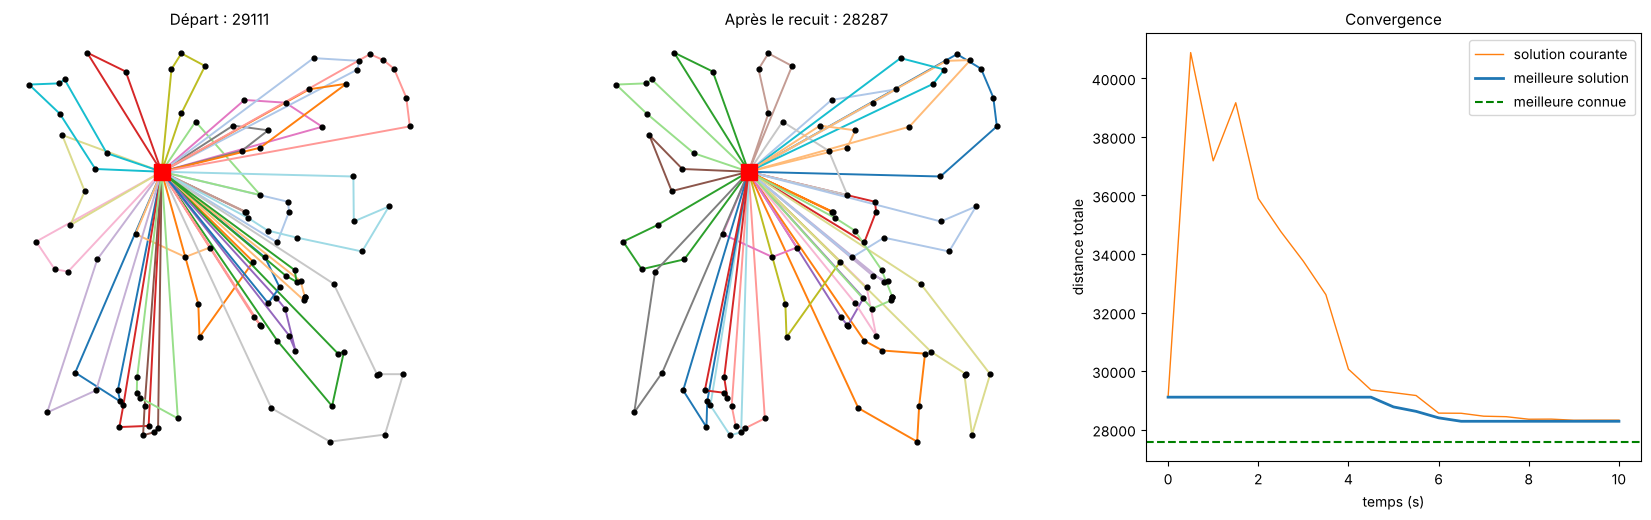

In [12]:
import json

bks = json.load(open("bks.json"))
bks.update(json.load(open("bks_solomon.json")))


def ecart(cout, nom):
    # gap en % par rapport à la meilleure solution connue
    return 100 * (cout - bks[nom]) / bks[nom]


def tracer_solution(inst, routes, ax, titre):
    # dessine les tournées d'une solution (une couleur par tournée)
    xy = inst["coords"]
    couleurs = plt.cm.tab20.colors
    for r, tour in enumerate(routes):
        chemin = [0] + tour + [0]
        ax.plot([xy[c][0] for c in chemin], [xy[c][1] for c in chemin], "-", color=couleurs[r % 20], lw=1.4)
    ax.scatter([p[0] for p in xy[1:]], [p[1] for p in xy[1:]], s=12, color="black", zorder=3)
    ax.scatter(xy[0][0], xy[0][1], s=120, marker="s", color="red", zorder=4)
    ax.set_title(titre, fontsize=11)
    ax.set_aspect("equal")
    ax.axis("off")


def demonstration(inst, nom, duree):
    # résout l'instance, affiche les chiffres, dessine départ / résultat / convergence
    res = resoudre(inst, duree=duree, graine=1)
    print(f"{nom} : {res['message']}")
    print(f"  départ (Clarke et Wright) : {res['cout_initial']:.1f}  (gap {ecart(res['cout_initial'], nom):.2f} %)")
    print(f"  après le recuit           : {res['cout']:.1f}  (gap {ecart(res['cout'], nom):.2f} %)")
    print(f"  meilleure solution connue : {bks[nom]}")
    print(f"  {len(res['routes'])} tournées, {res['iterations']:,} itérations en {duree} s")
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.3))
    tracer_solution(inst, res["routes_initiales"], axes[0], f"Départ : {res['cout_initial']:.0f}")
    tracer_solution(inst, res["routes"], axes[1], f"Après le recuit : {res['cout']:.0f}")
    temps = [p[0] for p in res["historique"]]
    axes[2].plot(temps, [p[1] for p in res["historique"]], color="tab:orange", lw=1, label="solution courante")
    axes[2].plot(temps, [p[2] for p in res["historique"]], color="tab:blue", lw=2, label="meilleure solution")
    axes[2].axhline(bks[nom], color="green", ls="--", label="meilleure connue")
    axes[2].set_xlabel("temps (s)")
    axes[2].set_ylabel("distance totale")
    axes[2].set_title("Convergence", fontsize=11)
    axes[2].legend()
    plt.tight_layout()
    plt.show()
    return res


inst_x = lire_instance("instances/X-n101-k25.vrp")
res_x = demonstration(inst_x, "X-n101-k25", 10)

**Ce que l'on voit.** La solution de départ a des tournées qui se croisent. Sur la courbe, la solution courante (orange) commence par se dégrader fortement : la température est haute et le programme accepte beaucoup de changements qui allongent le trajet. Quand la température baisse, la courbe redescend et finit sous la solution de départ, près de la meilleure solution connue.

### 6.2 Avec fenêtres de temps : `r101` et `c101` (100 clients)

`r101` a des clients placés au hasard et des fenêtres très étroites ; `c101` a des clients regroupés par paquets. L'optimum est connu pour les deux (1637,7 et 827,3).

r101 : solution valable
  départ (Clarke et Wright) : 1996.7  (gap 21.92 %)
  après le recuit           : 1640.6  (gap 0.18 %)
  meilleure solution connue : 1637.7
  20 tournées, 3,020,000 itérations en 10 s


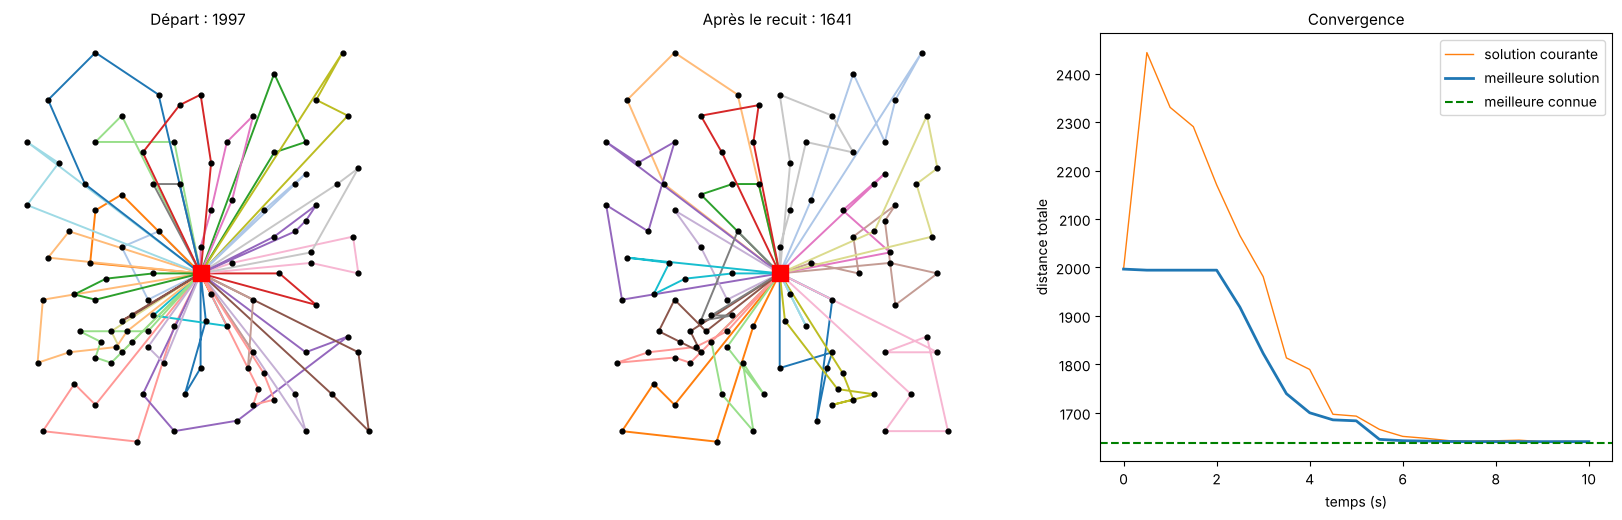

c101 : solution valable
  départ (Clarke et Wright) : 928.2  (gap 12.20 %)
  après le recuit           : 827.3  (gap 0.00 %)
  meilleure solution connue : 827.3
  10 tournées, 3,028,500 itérations en 10 s


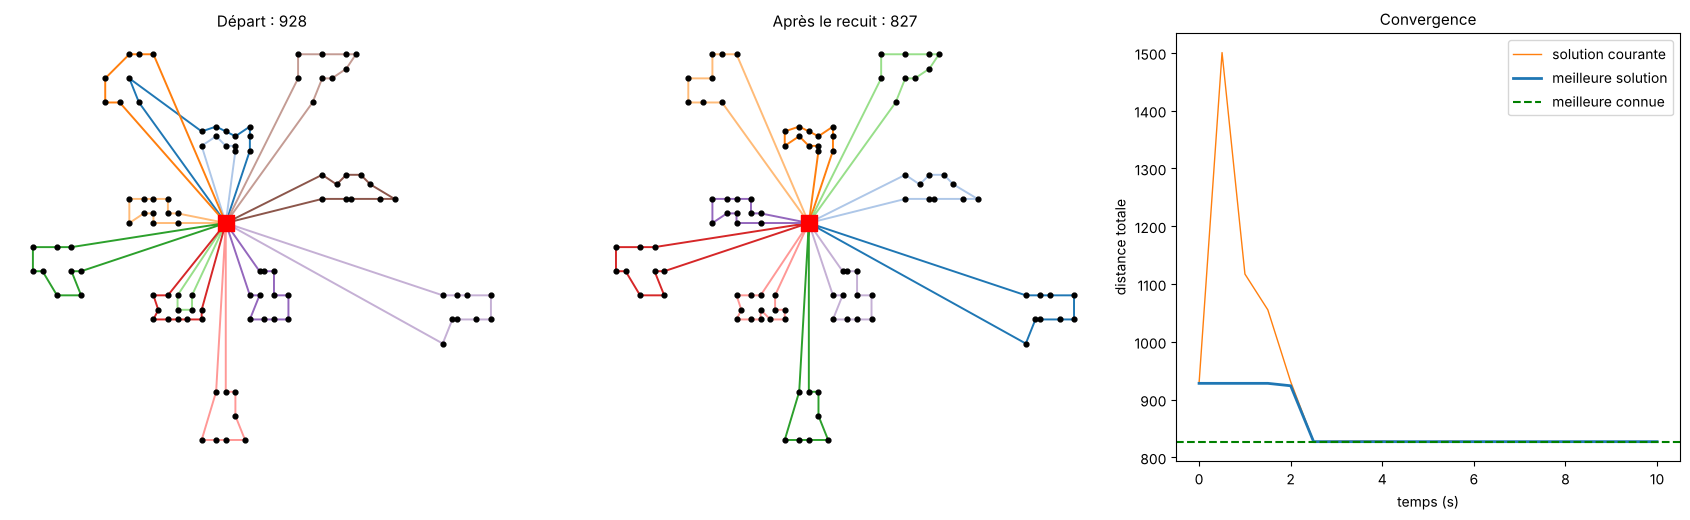

In [13]:
inst_r = lire_instance_solomon("solomon/r101.txt")
res_r = demonstration(inst_r, "r101", 10)
inst_c = lire_instance_solomon("solomon/c101.txt")
res_c = demonstration(inst_c, "c101", 10)

### 6.3 Les horaires d'une tournée

Pour une tournée de la solution de `r101`, on affiche l'heure d'arrivée chez chaque client, sa fenêtre, l'attente éventuelle et l'heure de départ. On voit que le camion attend quand il arrive avant l'ouverture, et qu'il n'arrive jamais après la fermeture.

In [14]:
D_r = calcul_distances(inst_r["coords"], inst_r["arrondi"])
tournee = max(res_r["routes"], key=len)          # la tournée avec le plus de clients
lignes = []
for c, (arrivee, attente, depart) in zip(tournee, horaires(tournee, D_r, inst_r["fenetres"], inst_r["services"])):
    a, b = inst_r["fenetres"][c]
    lignes.append({"client": c, "ouverture": a, "fermeture": b, "arrivée": round(arrivee, 1),
                   "attente": round(attente, 1), "départ": round(depart, 1),
                   "dans la fenêtre": a <= arrivee + attente <= b})
pd.DataFrame(lignes)

,client,ouverture,fermeture,arrivée,attente,départ,dans la fenêtre
0,28,39.0,49.0,6.3,32.7,49.0,True
1,12,63.0,73.0,58.2,4.8,73.0,True
2,76,73.0,83.0,80.0,0.0,90.0,True
3,79,92.0,102.0,100.0,0.0,110.0,True
4,3,116.0,126.0,113.6,2.4,126.0,True
5,54,140.0,150.0,142.1,0.0,152.1,True
6,24,153.0,163.0,162.1,0.0,172.1,True
7,80,182.0,192.0,181.3,0.7,192.0,True


In [15]:
# le même contrôle sur TOUTES les tournées des trois démonstrations, avec la fonction verifier
for nom, inst, res in [("X-n101-k25", inst_x, res_x), ("r101", inst_r, res_r), ("c101", inst_c, res_c)]:
    D = calcul_distances(inst["coords"], inst["arrondi"])
    ok, message = verifier(res["routes"], inst["demandes"], inst["Q"], None, D,
                           inst.get("fenetres"), inst.get("services"))
    print(f"{nom:12s} {message} | coût recalculé {cout_total(res['routes'], D):.1f}")

X-n101-k25   solution valable | coût recalculé 28287.0
r101         solution valable | coût recalculé 1640.6
c101         solution valable | coût recalculé 827.3


## 7. Validation sur les instances de référence

### 7.1 Les instances et le gap

| | CVRP (sans fenêtres) | CVRPTW (avec fenêtres) |
|---|---|---|
| **Instances** | 24 instances **X** de Uchoa et al. (2017), de 105 à 935 clients | les 56 instances de **Solomon** (1987), 100 clients |
| **Variété** | position du dépôt, clients au hasard ou regroupés, petites ou grosses demandes, de 6 à 151 tournées | 6 familles : clients regroupés (C), au hasard (R) ou mélangés (RC) ; fenêtres étroites et petits camions (type 1) ou fenêtres larges et gros camions (type 2) |
| **Référence** | meilleures solutions connues (fichiers `.sol` fournis avec les instances) | valeurs optimales publiées sur CVRPLIB |
| **Distances** | arrondies à l'entier le plus proche | coupées à une décimale |
| **Format** | VRPLIB (`.vrp`), lisible aussi avec la bibliothèque `vrplib` | format de Solomon (`.txt`) |

Pour chaque instance, on compare notre coût à la référence avec le **gap** :

$$\text{gap} = 100 \times \frac{\text{coût trouvé} - \text{coût de référence}}{\text{coût de référence}}$$

Un gap de 0 % signifie que l'on égale la référence. Pour les instances de Solomon la référence est l'optimum prouvé : le gap ne peut donc pas être négatif.

**Attention à l'objectif.** Pour les instances de Solomon, beaucoup d'articles minimisent d'abord le nombre de camions puis la distance. Nous minimisons **la distance seule**, comme le demande le sujet (durée totale) et comme le fait CVRPLIB : les valeurs de référence utilisées sont celles de cet objectif.

### 7.2 Contrôles

Trois contrôles évitent de se tromper sur les résultats :

1. **La convention de distance.** On recalcule avec nos fonctions le coût de la solution optimale connue de `c101` : on doit retrouver 827,3.
2. **La lecture des fichiers.** On relit une instance avec la bibliothèque `vrplib` et on compare avec notre fonction `lire_instance`.
3. **La validité.** Chaque solution des expériences est contrôlée par `verifier` (clients, capacité, fenêtres), et son coût est recalculé depuis zéro.

In [16]:
# 1) convention de distance : la solution optimale connue de c101 doit coûter 827,3
optimale_c101 = [[81, 78, 76, 71, 70, 73, 77, 79, 80],
                 [90, 87, 86, 83, 82, 84, 85, 88, 89, 91],
                 [98, 96, 95, 94, 92, 93, 97, 100, 99],
                 [57, 55, 54, 53, 56, 58, 60, 59],
                 [67, 65, 63, 62, 74, 72, 61, 64, 68, 66, 69],
                 [5, 3, 7, 8, 10, 11, 9, 6, 4, 2, 1, 75],
                 [13, 17, 18, 19, 15, 16, 14, 12],
                 [43, 42, 41, 40, 44, 46, 45, 48, 51, 50, 52, 49, 47],
                 [20, 24, 25, 27, 29, 30, 28, 26, 23, 22, 21],
                 [32, 33, 31, 35, 37, 38, 39, 36, 34]]
D_c = calcul_distances(inst_c["coords"], inst_c["arrondi"])
print("coût de la solution optimale de c101 avec nos fonctions :", round(cout_total(optimale_c101, D_c), 1),
      "| attendu :", bks["c101"], "|",
      verifier(optimale_c101, inst_c["demandes"], inst_c["Q"], None, D_c, inst_c["fenetres"], inst_c["services"])[1])

# 2) même instance lue avec la bibliothèque vrplib et avec notre fonction
import vrplib
officielle = vrplib.read_instance("instances/X-n101-k25.vrp")
print("lecture identique à vrplib :",
      [list(p) for p in officielle["node_coord"]] == [list(p) for p in inst_x["coords"]]
      and list(officielle["demand"]) == inst_x["demandes"] and officielle["capacity"] == inst_x["Q"])
officielle = vrplib.read_instance("solomon/c101.txt", instance_format="solomon")
print("lecture identique à vrplib (fichier de Solomon) :",
      [list(p) for p in officielle["node_coord"]] == [list(p) for p in inst_c["coords"]]
      and [list(f) for f in officielle["time_window"]] == [list(f) for f in inst_c["fenetres"]]
      and list(officielle["service_time"]) == inst_c["services"] and officielle["capacity"] == inst_c["Q"])

# 3) validité de toutes les solutions des deux études
cvrp = pd.read_csv("resultats/cvrp.csv")
cvrptw = pd.read_csv("resultats/cvrptw.csv")
for nom, df in [("CVRP", cvrp), ("CVRPTW", cvrptw)]:
    print(f"{nom:7s}: {len(df)} exécutions sur {df.instance.nunique()} instances | solutions valables : "
          f"{int(df.valide.sum())}/{len(df)} | écart max entre coût suivi et coût recalculé : {df.ecart_suivi.max()}")

coût de la solution optimale de c101 avec nos fonctions : 827.3 | attendu : 827.3 | solution valable
lecture identique à vrplib : True
lecture identique à vrplib (fichier de Solomon) : True


CVRP   : 72 exécutions sur 24 instances | solutions valables : 72/72 | écart max entre coût suivi et coût recalculé : 0
CVRPTW : 168 exécutions sur 56 instances | solutions valables : 168/168 | écart max entre coût suivi et coût recalculé : 0.0


## 8. Étude expérimentale

### 8.0 Le plan d'expérience

| N° | Question | Instances | Répétitions | Temps par exécution |
|---|---|---|---|---|
| 8.1 | Quels réglages ($t_0$, $t_1$, $K$) ? | 2 sans fenêtres (153 et 303 clients) + 2 avec (`r107`, `rc203`) | 2 graines | 10 s |
| 8.2 | Chaque mouvement est-il utile ? Le recuit apporte-t-il quelque chose ? | les 4 précédentes + `rc201`, `r201` | 2 graines | 10 s |
| 8.3 | Que gagne-t-on avec plus de temps ? | les 4 instances de réglage | 2 graines | 2 à 40 s |
| 8.4 | Qualité sur le CVRP | 24 instances X (105 à 935 clients) | 3 graines | 10 à 45 s selon la taille |
| 8.5 | Qualité sur le CVRPTW | 56 instances de Solomon | 3 graines | 20 s |
| 8.6 | Et sur de très grandes instances ? | 5 instances tirées au hasard (250 à 3000 clients) + `X-n1001-k43` | 1 à 2 graines | 60 s |

Toutes les expériences sont lancées par `experiences.py`, qui écrit un fichier CSV par expérience dans `resultats/`. Le notebook relit ces fichiers : on n'a pas besoin de refaire une heure et demie de calcul pour le relire. Les mesures ont été faites sur une machine à 2 cœurs, deux exécutions en parallèle.

**Indicateurs** : le gap (qualité), le temps de calcul, l'écart entre graines (robustesse), le nombre de tournées.

### 8.1 Réglage des paramètres

On fait varier un paramètre à la fois autour du réglage retenu ($t_0 = 2$, $t_1 = 0{,}01$, $K = 20$).

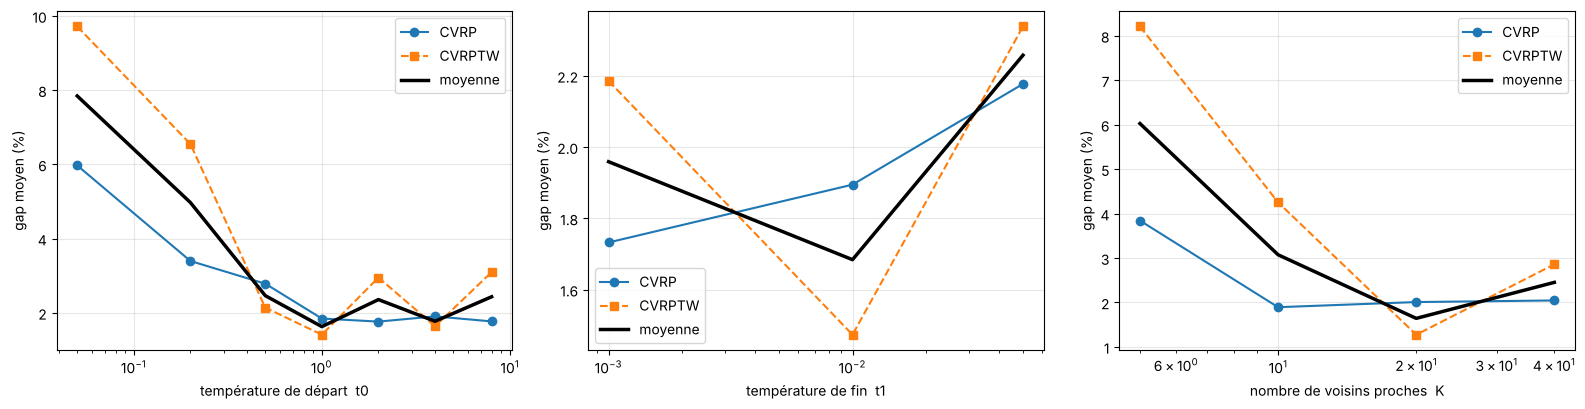

gap moyen du réglage retenu, mesuré trois fois : 2.36 %, 1.68 %, 1.64 %


t0,0.05,0.20,0.50,1.00,2.00,4.00,8.00
gap moyen (%),7.84,4.97,2.46,1.63,2.36,1.77,2.43


In [17]:
t0 = pd.read_csv("resultats/reglage_t0.csv")
t1 = pd.read_csv("resultats/reglage_t1.csv")
kk = pd.read_csv("resultats/reglage_K.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for df, colonne, ax, titre in [(t0, "t0", axes[0], "température de départ  t0"),
                                (t1, "t1", axes[1], "température de fin  t1"),
                                (kk, "K", axes[2], "nombre de voisins proches  K")]:
    for probleme, style in [("CVRP", "o-"), ("CVRPTW", "s--")]:
        g = df[df.probleme == probleme].groupby(colonne).gap.mean()
        ax.plot(g.index, g.values, style, label=probleme)
    g = df.groupby(colonne).gap.mean()
    ax.plot(g.index, g.values, "k-", lw=2.5, label="moyenne")
    ax.set_xscale("log")
    ax.set_xlabel(titre)
    ax.set_ylabel("gap moyen (%)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

# le même réglage (t0 = 2, t1 = 0,01, K = 20) a été mesuré dans les trois fichiers : cela donne une idée du bruit
memes = [df[(df.t0 == 2.0) & (df.t1 == 0.01) & (df.K == 20)].gap.mean() for df in (t0, t1, kk)]
print("gap moyen du réglage retenu, mesuré trois fois :", ", ".join(f"{m:.2f} %" for m in memes))
display(t0.groupby("t0").gap.mean().round(2).to_frame("gap moyen (%)").T)

**Ce que l'on lit.**

- **$t_0$** : avec une température de départ trop basse ($t_0 \le 0{,}2$), le recuit se comporte presque comme une simple descente et reste coincé (gap moyen de 5 à 8 %). À partir de $t_0 = 1$ le gap moyen reste autour de 2 %.
- **Le bruit est important.** Le même réglage, mesuré trois fois, donne 2,36 %, 1,68 % et 1,64 %. La raison : la température dépend du temps écoulé, donc deux exécutions avec la même graine ne font pas exactement le même nombre d'itérations. Avec 2 graines et 4 instances, un écart de moins de 0,7 point entre deux réglages ne veut rien dire.
- **Conséquence** : entre $t_0 = 1$, 2 et 4 (1,63 %, 2,36 %, 1,77 %) on ne peut pas départager. Nous avons retenu **$t_0 = 2$**, au milieu de ce plateau, plutôt que le minimum qui change d'un lancement à l'autre.
- **$t_1$** : les trois valeurs sont proches (1,7 à 2,3 %). Nous gardons $t_1 = 0{,}01$.
- **$K$** : l'effet le plus net. Avec 5 voisins le recuit rate beaucoup de changements utiles (6,0 %), avec 10 c'est encore insuffisant (3,1 %). Entre 20 et 40 la différence (1,6 % et 2,5 %) est dans le bruit ; nous gardons **$K = 20$**.

**Réglage retenu : $t_0 = 2$, $t_1 = 0{,}01$, $K = 20$.** Deux des quatre instances de réglage font aussi partie de l'étude 8.5 (`r107`, `rc203`), aucune de l'étude 8.4.

### 8.2 Que valent les différents mouvements ? (ablation)

On relance le solveur en **retirant un mouvement à la fois**, et on teste une **descente seule** (température nulle : on n'accepte que les améliorations, donc pas de recuit). Si retirer un mouvement augmente le gap, c'est qu'il aide. Le mouvement « nouvelle tournée » n'est utilisé qu'avec des fenêtres de temps (voir l'explication sous le tableau).

,CVRP : gap moyen (%),CVRPTW : gap moyen (%)
variante,,
tous les mouvements,1.77,1.97
sans déplacer,2.05,6.27
sans échanger,2.10,3.24
sans 2-opt,2.08,2.56
sans 2-opt*,2.82,3.43
sans nouvelle tournée,NaN,3.03
descente seule (T = 0),6.71,21.35


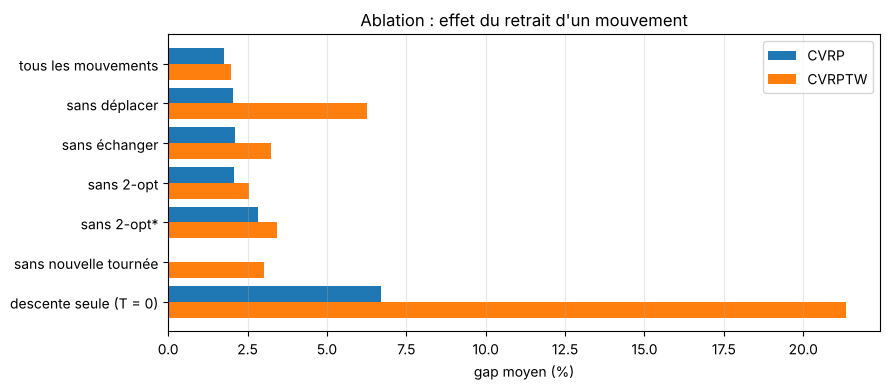

In [18]:
ab = pd.read_csv("resultats/ablation.csv")
tab = ab.groupby(["variante", "probleme"], sort=False).gap.mean().unstack().round(2)
tab.columns = ["CVRP : gap moyen (%)", "CVRPTW : gap moyen (%)"]
display(tab)

fig, ax = plt.subplots(figsize=(9, 4))
t = tab.iloc[::-1]
y = range(len(t))
ax.barh([i + 0.2 for i in y], t.iloc[:, 0], height=0.4, label="CVRP")
ax.barh([i - 0.2 for i in y], t.iloc[:, 1], height=0.4, label="CVRPTW")
ax.set_yticks(list(y))
ax.set_yticklabels(t.index)
ax.set_xlabel("gap moyen (%)")
ax.set_title("Ablation : effet du retrait d'un mouvement")
ax.grid(axis="x", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Ce que l'on lit.**

- **Le recuit est indispensable.** La descente seule finit à 6,7 % (CVRP) et 21 % (CVRPTW), contre 1,8 % et 2,0 % avec le recuit. C'est l'acceptation de mauvais changements qui fait la qualité, surtout avec des fenêtres de temps où la descente se bloque très vite.
- **Avec fenêtres de temps, tous les mouvements comptent.** Retirer « déplacer » fait passer le gap de 2,0 % à 6,3 %. Retirer « échanger », « 2-opt\* » ou « nouvelle tournée » coûte environ un point.
- **« Nouvelle tournée » n'est utilisé qu'avec des fenêtres.** Sans lui, le gap passe de 2,0 % à 3,0 % sur ces six instances. En revanche, sur le CVRP nous l'avons essayé et il dégradait une instance où les camions sont presque pleins (`X-n153-k22`, de 0,9 % à plus de 3 %) : un client mis seul dans un camion ne peut plus être repris par les autres. Nous l'avons donc désactivé quand il n'y a pas de fenêtres.
- **Sans fenêtres**, « 2-opt\* » est le mouvement le plus utile (2,8 % sans lui). Pour les trois autres, l'écart (0,3 point) est du même ordre que le bruit : on ne peut pas conclure.

### 8.3 Effet du temps de calcul

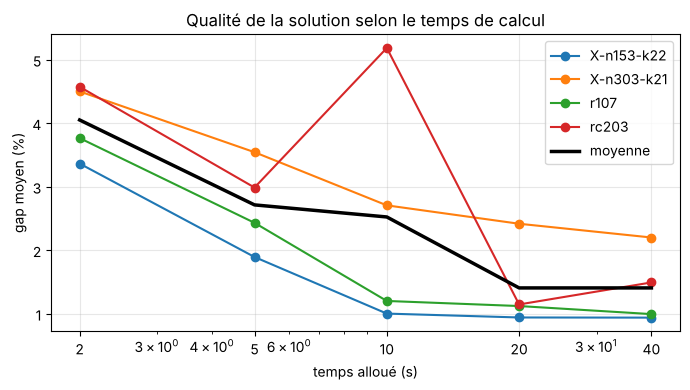

duree,2,5,10,20,40
instance,,,,,
X-n153-k22,3.36,1.89,1.00,0.94,0.94
X-n303-k21,4.50,3.54,2.71,2.42,2.20
r107,3.77,2.43,1.20,1.12,1.00
rc203,4.57,2.99,5.19,1.15,1.49


In [19]:
bu = pd.read_csv("resultats/budget.csv")
g = bu.groupby(["instance", "duree"]).gap.mean().unstack()
fig, ax = plt.subplots(figsize=(7, 4))
for nom in g.index:
    ax.plot(g.columns, g.loc[nom], "o-", label=nom)
ax.plot(g.columns, g.mean(), "k-", lw=2.5, label="moyenne")
ax.set_xscale("log")
ax.set_xticks(list(g.columns))
ax.set_xticklabels(list(g.columns))
ax.set_xlabel("temps alloué (s)")
ax.set_ylabel("gap moyen (%)")
ax.set_title("Qualité de la solution selon le temps de calcul")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
display(g.round(2))

**Ce que l'on lit.** En moyenne, le gap passe d'environ 4,1 % à 2 secondes à 1,4 % à 20 secondes, puis il ne bouge presque plus à 40 secondes. Le gain est donc fort au début puis il sature : sur ces instances de 100 à 300 clients, 20 secondes suffisent. La courbe n'est pas parfaitement régulière (par exemple `rc203` à 10 secondes) parce que seulement 2 graines sont moyennées.

### 8.4 Résultats sur le CVRP : 24 instances X

Chaque instance est résolue avec 3 graines. Le temps alloué dépend de la taille : 10 s jusqu'à 200 clients, 20 s jusqu'à 400, 30 s jusqu'à 700, 45 s au-delà.

In [20]:
from scipy import stats

par = cvrp.groupby(["instance", "n"]).agg(
    bks=("bks", "first"), duree=("duree", "first"), routes=("routes", "mean"),
    gap_depart=("gap_init", "mean"), gap_min=("gap", "min"), gap_moyen=("gap", "mean"),
    gap_max=("gap", "max"), ecart_type=("gap", "std"),
    iterations=("iterations", "mean")).reset_index().sort_values("n")
par["iter_par_client"] = (par.iterations / par.n).round(0)
display(par.drop(columns="iterations").round(2).reset_index(drop=True))

print(f"Gap moyen sur les 24 instances : {par.gap_moyen.mean():.2f} %  (médiane {par.gap_moyen.median():.2f} %)")
print(f"Plus mauvaise instance         : {par.gap_moyen.max():.2f} %   | plus mauvaise exécution : {cvrp.gap.max():.2f} %")
print(f"Gap de la solution de départ   : {par.gap_depart.mean():.2f} %")
print(f"Écart-type moyen entre graines : {par.ecart_type.mean():.2f} point de gap")
print(f"Wilcoxon (départ contre recuit, 24 instances) : p = {stats.wilcoxon(par.gap_depart, par.gap_moyen).pvalue:.1e}")
rho, p = stats.spearmanr(par.n, par.gap_moyen)
print(f"Spearman (taille, gap moyen) : rho = {rho:.2f}, p = {p:.3f}")
rho, p = stats.spearmanr(par.iter_par_client, par.gap_moyen)
print(f"Spearman (itérations par client, gap moyen) : rho = {rho:.2f}, p = {p:.3f}")

,instance,n,bks,duree,routes,gap_depart,gap_min,gap_moyen,gap_max,ecart_type,iter_par_client
0,X-n106-k14,105,26362,10,14.00,3.84,0.89,1.13,1.49,0.32,37048.0
1,X-n110-k13,109,14971,10,13.00,5.93,0.43,0.86,1.60,0.64,36159.0
2,X-n120-k6,119,13332,10,6.00,9.07,0.86,1.94,2.66,0.95,23254.0
3,X-n125-k30,124,55539,10,31.00,4.57,1.63,2.07,2.47,0.42,32242.0
4,X-n176-k26,175,47812,10,27.00,9.93,2.27,2.37,2.48,0.11,20195.0
5,X-n190-k8,189,16980,10,8.00,6.12,1.78,2.36,3.42,0.92,13635.0
6,X-n275-k28,274,21245,20,28.00,5.77,1.09,1.57,1.90,0.43,23980.0
7,X-n280-k17,279,33503,20,17.00,8.29,1.93,1.95,1.97,0.02,19790.0
8,X-n289-k60,288,95151,20,62.33,3.22,1.20,1.58,1.81,0.33,25377.0
9,X-n294-k50,293,47161,20,51.33,2.78,1.02,1.44,1.76,0.38,24965.0


Gap moyen sur les 24 instances : 2.10 %  (médiane 2.06 %)
Plus mauvaise instance         : 3.42 %   | plus mauvaise exécution : 4.40 %
Gap de la solution de départ   : 5.36 %
Écart-type moyen entre graines : 0.33 point de gap
Wilcoxon (départ contre recuit, 24 instances) : p = 2.7e-05
Spearman (taille, gap moyen) : rho = 0.56, p = 0.004
Spearman (itérations par client, gap moyen) : rho = -0.61, p = 0.002


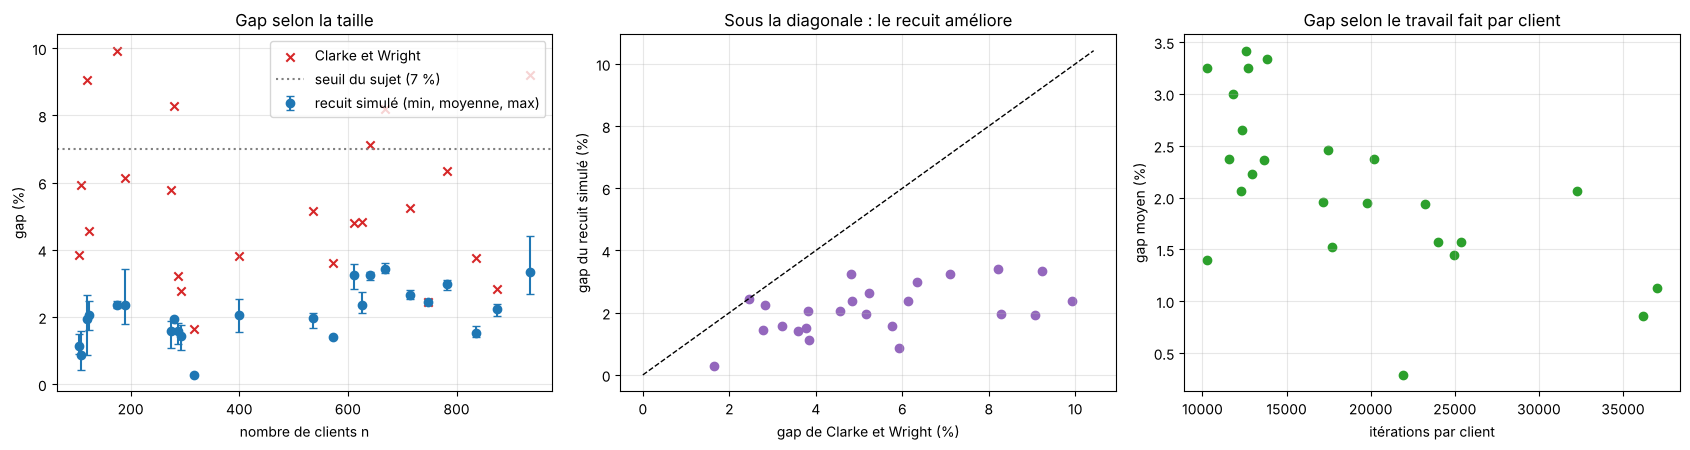

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

axes[0].errorbar(par.n, par.gap_moyen, yerr=[par.gap_moyen - par.gap_min, par.gap_max - par.gap_moyen],
                 fmt="o", capsize=3, label="recuit simulé (min, moyenne, max)")
axes[0].scatter(par.n, par.gap_depart, marker="x", color="tab:red", label="Clarke et Wright")
axes[0].axhline(7, color="gray", ls=":", label="seuil du sujet (7 %)")
axes[0].set_xlabel("nombre de clients n")
axes[0].set_ylabel("gap (%)")
axes[0].set_title("Gap selon la taille")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].scatter(par.gap_depart, par.gap_moyen, color="tab:purple")
limite = par.gap_depart.max() * 1.05
axes[1].plot([0, limite], [0, limite], "k--", lw=1)
axes[1].set_xlabel("gap de Clarke et Wright (%)")
axes[1].set_ylabel("gap du recuit simulé (%)")
axes[1].set_title("Sous la diagonale : le recuit améliore")
axes[1].grid(alpha=0.3)

axes[2].scatter(par.iter_par_client, par.gap_moyen, color="tab:green")
axes[2].set_xlabel("itérations par client")
axes[2].set_ylabel("gap moyen (%)")
axes[2].set_title("Gap selon le travail fait par client")
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Ce que l'on lit.**

- Les 72 solutions sont valables et le coût suivi est toujours égal au coût recalculé.
- Le **gap moyen est de 2,1 %**, la plus mauvaise instance est à 3,4 % et la plus mauvaise exécution à 4,4 % : on reste nettement sous le seuil de 7 % du sujet. La solution de départ est à 5,4 % en moyenne ; le recuit enlève donc environ 60 % du retard sur la meilleure solution connue.
- Le résultat est **stable d'une graine à l'autre** (écart-type moyen affiché ci-dessus), ce qui rend la moyenne sur 3 graines fiable.
- **Le gap augmente avec la taille** (corrélation de Spearman ci-dessus). L'explication est dans le troisième graphique : le temps alloué augmente moins vite que la taille, donc les grandes instances reçoivent moins d'itérations par client.
- **Un cas d'échec** : sur `X-n749-k98`, le recuit n'améliore pas la solution de départ sur les 3 graines (gap identique de 2,46 %). La température de départ est trop haute pour le temps alloué : la solution est d'abord dégradée, et la fin du refroidissement est trop courte pour revenir sous le niveau de départ. On retrouve ce problème en 8.6.

### 8.5 Résultats sur le CVRPTW : 56 instances de Solomon

Chaque instance (100 clients) est résolue avec 3 graines de 20 secondes. On regroupe les résultats par famille pour voir l'effet de la répartition des clients et de la largeur des fenêtres.

In [22]:
cvrptw["famille"] = cvrptw.instance.str.slice(0, -2).str.upper()
par_tw = cvrptw.groupby(["famille", "instance"]).agg(
    optimum=("bks", "first"), routes=("routes", "mean"), gap_depart=("gap_init", "mean"),
    gap_min=("gap", "min"), gap_moyen=("gap", "mean"), gap_max=("gap", "max"),
    ecart_type=("gap", "std")).reset_index()

familles = par_tw.groupby("famille").agg(
    instances=("instance", "count"), routes=("routes", "mean"), gap_depart=("gap_depart", "mean"),
    gap_moyen=("gap_moyen", "mean"), pire_instance=("gap_moyen", "max"),
    optimum_atteint=("gap_min", lambda s: int((s < 0.005).sum()))).round(2)
description = {"C1": "regroupés, fenêtres étroites", "C2": "regroupés, fenêtres larges",
               "R1": "au hasard, fenêtres étroites", "R2": "au hasard, fenêtres larges",
               "RC1": "mélangés, fenêtres étroites", "RC2": "mélangés, fenêtres larges"}
familles.insert(0, "clients et fenêtres", [description[f] for f in familles.index])
display(familles)

print(f"Gap moyen sur les 56 instances : {par_tw.gap_moyen.mean():.2f} %  (médiane {par_tw.gap_moyen.median():.2f} %)")
print(f"Plus mauvaise instance         : {par_tw.gap_moyen.max():.2f} % ({par_tw.loc[par_tw.gap_moyen.idxmax(), 'instance']})"
      f"   | plus mauvaise exécution : {cvrptw.gap.max():.2f} %")
print(f"Gap de la solution de départ   : {par_tw.gap_depart.mean():.2f} %")
print(f"Instances où l'optimum est atteint au moins une fois : {(par_tw.gap_min < 0.005).sum()} / 56")
print(f"Instances avec un gap moyen < 1 % : {(par_tw.gap_moyen < 1).sum()} | < 3 % : {(par_tw.gap_moyen < 3).sum()}"
      f" | < 7 % : {(par_tw.gap_moyen < 7).sum()}")
print(f"Écart-type moyen entre graines : {par_tw.ecart_type.mean():.2f} point de gap")
groupes = [par_tw[par_tw.famille == f].gap_moyen for f in familles.index]
print(f"Kruskal-Wallis (les 6 familles ont-elles le même gap ?) : p = {stats.kruskal(*groupes).pvalue:.1e}")

,clients et fenêtres,instances,routes,gap_depart,gap_moyen,pire_instance,optimum_atteint
famille,,,,,,,
C1,"regroupés, fenêtres étroites",9,10.00,9.80,0.16,1.32,7
C2,"regroupés, fenêtres larges",8,3.00,19.48,0.12,0.99,8
R1,"au hasard, fenêtres étroites",12,13.67,16.46,1.39,2.44,0
R2,"au hasard, fenêtres larges",11,5.73,19.77,1.36,1.80,0
RC1,"mélangés, fenêtres étroites",8,13.42,17.77,1.93,3.60,0
RC2,"mélangés, fenêtres larges",8,6.83,26.06,2.28,3.12,0


Gap moyen sur les 56 instances : 1.21 %  (médiane 1.32 %)
Plus mauvaise instance         : 3.60 % (rc108)   | plus mauvaise exécution : 5.55 %
Gap de la solution de départ   : 18.03 %
Instances où l'optimum est atteint au moins une fois : 15 / 56
Instances avec un gap moyen < 1 % : 22 | < 3 % : 54 | < 7 % : 56
Écart-type moyen entre graines : 0.49 point de gap
Kruskal-Wallis (les 6 familles ont-elles le même gap ?) : p = 6.9e-07


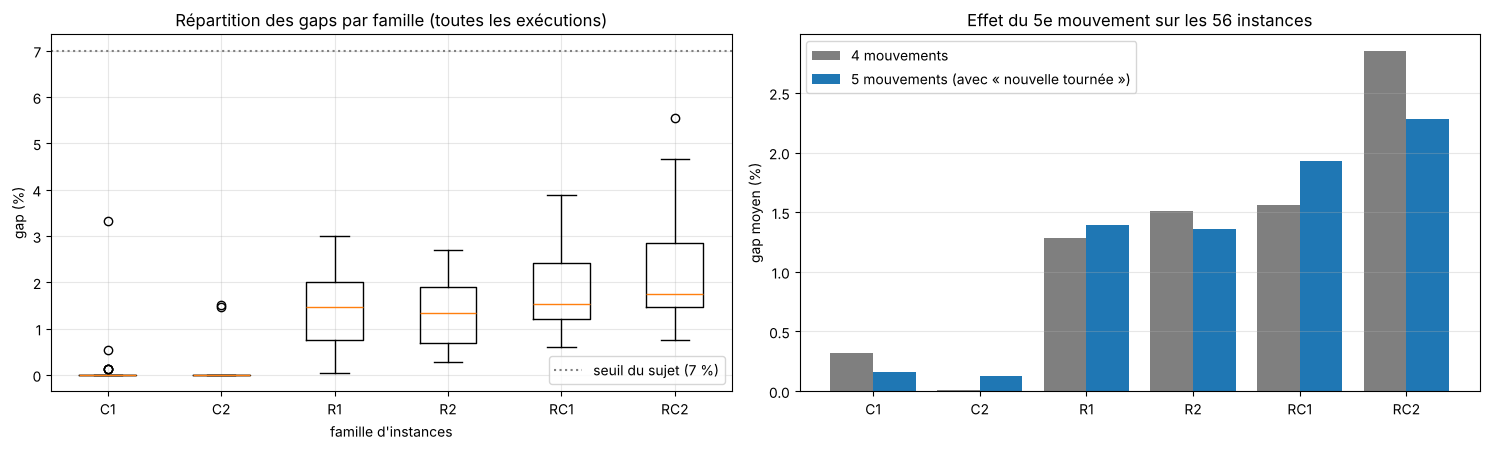

gap moyen avec 4 mouvements : 1.25 %  |  avec 5 mouvements : 1.21 %


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

ordre = list(familles.index)
axes[0].boxplot([cvrptw[cvrptw.famille == f].gap for f in ordre])
axes[0].set_xticklabels(ordre)
axes[0].axhline(7, color="gray", ls=":", label="seuil du sujet (7 %)")
axes[0].set_xlabel("famille d'instances")
axes[0].set_ylabel("gap (%)")
axes[0].set_title("Répartition des gaps par famille (toutes les exécutions)")
axes[0].grid(alpha=0.3)
axes[0].legend()

# avant / après l'ajout du mouvement "nouvelle tournée" (voir 8.2)
avant = pd.read_csv("resultats/cvrptw_4_mouvements.csv")
avant["famille"] = avant.instance.str.slice(0, -2).str.upper()
a = avant.groupby("famille").gap.mean()
b = cvrptw.groupby("famille").gap.mean()
x = range(len(ordre))
axes[1].bar([i - 0.2 for i in x], [a[f] for f in ordre], width=0.4, label="4 mouvements", color="tab:gray")
axes[1].bar([i + 0.2 for i in x], [b[f] for f in ordre], width=0.4, label="5 mouvements (avec « nouvelle tournée »)")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(ordre)
axes[1].set_ylabel("gap moyen (%)")
axes[1].set_title("Effet du 5e mouvement sur les 56 instances")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"gap moyen avec 4 mouvements : {avant.gap.mean():.2f} %  |  avec 5 mouvements : {cvrptw.gap.mean():.2f} %")

**Ce que l'on lit.**

- Les 168 solutions respectent la capacité et **toutes les fenêtres de temps**.
- Le **gap moyen est de 1,2 %** par rapport à l'optimum. La plus mauvaise instance est à 3,6 % et la plus mauvaise exécution à 5,6 % : toutes sont sous le seuil de 7 %. La solution de départ est en moyenne à 18 % : avec des fenêtres, Clarke et Wright est beaucoup moins bon, et le recuit fait l'essentiel du travail.
- **L'optimum est atteint au moins une fois sur 15 instances**, toutes dans les familles C (clients regroupés). Sur les familles R et RC il n'est jamais atteint en 20 secondes.
- **Les familles ne se valent pas** (test de Kruskal-Wallis ci-dessus). Quand les clients sont regroupés (C1, C2), le gap est presque nul : les tournées naturelles sont les paquets de clients. Quand ils sont au hasard ou mélangés (R, RC), le gap est de 1,4 à 2,3 %. C'est donc la **répartition des clients** qui joue le plus. La largeur des fenêtres joue peu : R1 et R2 sont au même niveau (1,4 %), RC2 est un peu au-dessus de RC1.
- **Le cinquième mouvement** change peu la moyenne sur les 56 instances (1,25 % puis 1,21 %), mais il corrige les plus mauvais cas : la pire instance passe de 5,2 % à 3,6 % et la pire exécution de 7,6 % à 5,6 %. Son effet est surtout visible sur la famille RC2 (2,9 % puis 2,3 %) et sur les petites instances de la partie 3. Sur C2, R1 et RC1 le gap est un peu moins bon qu'avant (par exemple 1,6 % puis 1,9 % sur RC1) : avec 3 graines nous ne savons pas dire si c'est un effet réel ou du bruit.

### 8.6 Temps de calcul et très grandes instances

Le sujet parle de plusieurs milliers de clients. Nous avons tiré au hasard des instances de 250 à 3000 clients (pas de meilleure solution connue : on mesure le gain par rapport à la solution de départ) et chronométré chaque étape. Le recuit a 60 secondes. On compare le réglage retenu ($t_0 = 2$) à un départ plus froid ($t_0 = 0{,}2$). Pour avoir aussi un vrai gap, on ajoute l'instance de référence `X-n1001-k43` (1000 clients).

,t_distances,t_voisins,t_depart,préparation totale (s),"gain du recuit en 60 s, t0 = 0.2 (%)","gain du recuit en 60 s, t0 = 2.0 (%)",iterations,routes
n,,,,,,,,
250,0.02,0.01,0.02,0.05,7.93,7.97,16001000,14
500,0.09,0.06,0.14,0.29,6.56,7.12,13493500,28
1000,0.24,0.19,0.50,0.93,4.46,4.68,14591000,52
2000,1.05,0.67,1.97,3.69,1.40,0.00,15667000,106
3000,2.14,1.80,4.70,8.64,1.46,0.00,14440000,159


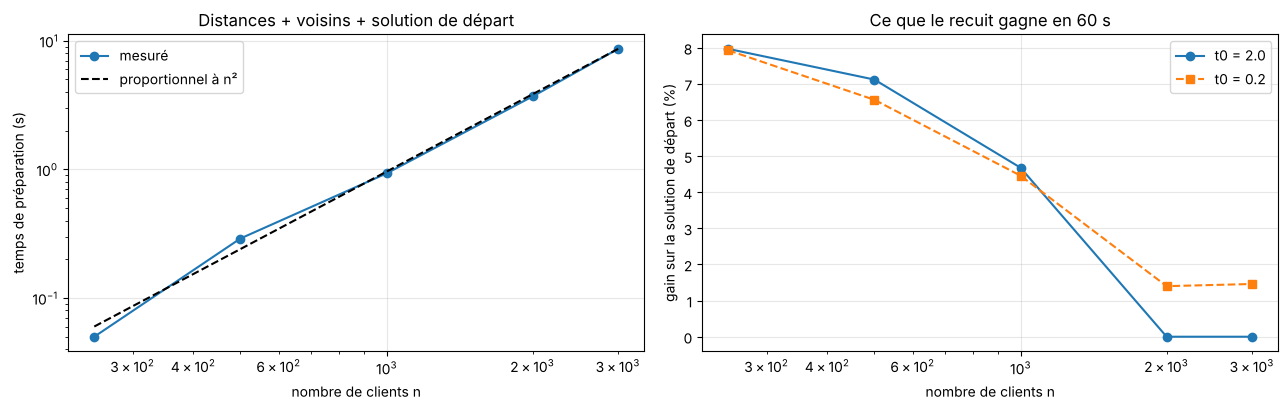

,gap_depart,gap_moyen
t0,,
0.2,6.67,4.04
2.0,6.67,4.01


In [24]:
ta = pd.read_csv("resultats/taille.csv")
prepa = ta[ta.t0 == 2.0][["n", "t_distances", "t_voisins", "t_depart"]].set_index("n")
prepa["préparation totale (s)"] = prepa.sum(axis=1)
gain = ta.pivot(index="n", columns="t0", values="gain_pct")
gain.columns = [f"gain du recuit en 60 s, t0 = {c} (%)" for c in gain.columns]
display(prepa.join(gain).join(ta[ta.t0 == 2.0].set_index("n")[["iterations", "routes"]]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].loglog(prepa.index, prepa["préparation totale (s)"], "o-", label="mesuré")
n0, t_ref = prepa.index[-1], prepa["préparation totale (s)"].iloc[-1]
axes[0].loglog(prepa.index, [t_ref * (n / n0) ** 2 for n in prepa.index], "k--", label="proportionnel à n²")
axes[0].set_xlabel("nombre de clients n")
axes[0].set_ylabel("temps de préparation (s)")
axes[0].set_title("Distances + voisins + solution de départ")
axes[0].grid(alpha=0.3)
axes[0].legend()
for t0_val, style in [(2.0, "o-"), (0.2, "s--")]:
    sous = ta[ta.t0 == t0_val]
    axes[1].plot(sous.n, sous.gain_pct, style, label=f"t0 = {t0_val}")
axes[1].set_xscale("log")
axes[1].set_xlabel("nombre de clients n")
axes[1].set_ylabel("gain sur la solution de départ (%)")
axes[1].set_title("Ce que le recuit gagne en 60 s")
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()

grande = pd.read_csv("resultats/grande.csv")
display(grande.groupby("t0").agg(gap_depart=("gap_init", "mean"), gap_moyen=("gap", "mean")).round(2))

**Ce que l'on lit.**

- **La préparation** (distances, voisins, solution de départ) prend moins d'une seconde jusqu'à 1000 clients et environ 9 secondes à 3000. Elle grandit comme $n^2$ (la droite pointillée), parce qu'on calcule toutes les distances et toutes les économies. La mémoire suit la même loi : c'est ce qui limitera en premier au-delà de quelques milliers de clients.
- **Une itération du recuit coûte à peu près le même temps quelle que soit la taille** (environ 14 à 16 millions d'itérations en 60 secondes partout). Mais il y a plus de clients à améliorer : à 3000 clients, cela fait 12 fois moins d'itérations par client qu'à 250.
- **Avec le réglage retenu ($t_0 = 2$), le recuit ne gagne plus rien à 2000 et 3000 clients** en 60 secondes : la solution rendue est celle de départ. Avec un départ plus froid ($t_0 = 0{,}2$), il gagne 1,4 à 1,5 %. Le bon $t_0$ dépend donc du nombre d'itérations par client, alors que nous l'avons réglé sur des instances de 100 à 300 clients.
- Sur l'instance de référence de 1000 clients (`X-n1001-k43`), le gap est d'environ 4 % en 60 secondes avec les deux réglages (solution de départ : 6,7 %).

Notre programme **traite** donc des instances de plusieurs milliers de clients (solutions valables en un peu plus d'une minute), mais sur ces tailles la qualité vient surtout de la solution de départ.

## 9. Conclusion, limites et améliorations

**Ce que nous avons fait.** Nous avons modélisé le problème de tournées avec capacité et fenêtres de temps (graphe complet, minimisation du temps de trajet), montré qu'il est NP-difficile par réduction du cycle hamiltonien, et écrit un PLNE complet avec les variables $x_{ijkt}$ (camion et tranche horaire), les fenêtres et l'attente. La méthode exacte prouve l'optimum jusqu'à 12 clients sans fenêtres et 60 clients avec fenêtres, pas au-delà en 60 secondes. Nous avons donc programmé un **recuit simulé** qui traite les deux problèmes avec le même code.

| | CVRP (niveau B) | CVRPTW (niveau A) |
|---|---|---|
| Instances de référence | 24 instances X, 105 à 935 clients | 56 instances de Solomon, 100 clients |
| Exécutions | 72 (3 graines) | 168 (3 graines) |
| Temps par exécution | 10 à 45 s | 20 s |
| Solutions valables | 100 % | 100 % |
| **Gap moyen** | **2,1 %** | **1,2 %** |
| Plus mauvaise instance | 3,4 % | 3,6 % |
| Plus mauvaise exécution | 4,4 % | 5,6 % |

**Limites.**

- **Grandes instances** : au-delà de 1000 clients et avec peu de temps, le recuit n'améliore presque plus la solution de départ (8.6). Le réglage de $t_0$ ne convient qu'aux tailles sur lesquelles il a été fait.
- **Pas de garantie** : la méthode ne prouve pas l'optimalité, et sans fenêtres nous comparons à des meilleures solutions connues qui ne sont pas toutes prouvées optimales.
- **Résultats pas exactement reproductibles** : la température suit l'horloge, donc deux exécutions avec la même graine peuvent différer (8.1). Les petits écarts entre réglages ou entre mouvements ne sont pas fiables avec 2 graines.
- **Trafic** : les tranches horaires sont dans le PLNE (2.4) mais pas dans le recuit, car les instances de référence n'ont pas de trafic. Les distances sont euclidiennes, pas des durées sur un vrai réseau routier.
- **Avec fenêtres, une seule taille testée** (100 clients). Nous n'avons pas mesuré le recuit avec fenêtres sur 200 clients ou plus.
- **Nombre de camions** : nous minimisons la distance, pas le nombre de camions. Avec des fenêtres larges nos solutions utilisent parfois plus de camions que les solutions de la littérature qui minimisent d'abord la flotte.
- **Un seul type de métaheuristique** est évalué ici ; nous ne l'avons pas comparé à une autre (recherche tabou, ALNS) sur les mêmes instances.
- **Machine** : mesures faites sur 2 cœurs, en Python pur. Les temps dépendent de la machine.

**Améliorations possibles** (justifiées par les observations).

- Adapter la température de départ à la taille et au temps disponible (8.6), ou la remplacer par un nombre d'itérations par client : cela rendrait aussi les exécutions reproductibles (8.1).
- Pour les grandes instances : ne calculer les économies de Clarke et Wright que pour les voisins proches (préparation en $n \times K$ au lieu de $n^2$), et compiler la boucle du recuit (numba), ce qui multiplie le nombre d'itérations.
- Ajouter le trafic par tranche horaire dans le contrôle des horaires du recuit : la fonction `horaires_ok` parcourt déjà la tournée avec une horloge, il suffirait de lire la durée du trajet selon l'heure de départ.
- Ajouter un mouvement qui retire plusieurs clients à la fois et les réinsère (destruction / reconstruction), utile pour les familles R et RC et pour réduire le nombre de camions.
- Refaire le réglage avec plus de graines et sur des instances séparées de celles de l'évaluation.

## 10. Sources

- Uchoa, E., Pecin, D., Pessoa, A., Poggi, M., Vidal, T., Subramanian, A. (2017). *New benchmark instances for the Capacitated Vehicle Routing Problem*. European Journal of Operational Research, 257(3).
- Solomon, M. M. (1987). *Algorithms for the vehicle routing and scheduling problems with time window constraints*. Operations Research, 35(2).
- CVRPLIB, *All instances* (instances et valeurs de référence X et Solomon) : https://galgos.inf.puc-rio.br/cvrplib/en/instances
- Clarke, G., Wright, J. W. (1964). *Scheduling of vehicles from a central depot to a number of delivery points*. Operations Research, 12(4).
- Kirkpatrick, S., Gelatt, C. D., Vecchi, M. P. (1983). *Optimization by simulated annealing*. Science, 220.
- Karp, R. M. (1972). *Reducibility among combinatorial problems*.
- Savelsbergh, M. W. P. (1985). *Local search in routing problems with time windows*. Annals of Operations Research, 4.
- Bibliothèques : `vrplib` (lecture des instances), PuLP avec le solveur HiGHS (PLNE), pandas, matplotlib, scipy.